# 03 · Modelado de la serie semanal

Predecir la **venta neta semanal** de la tienda, con un modelo que se pueda
explicar a quien la gestiona.

**Resultado:** una **regresión lineal con cinco términos de calendario**
—constante, tendencia, horas de cierre en festivo, Semana Santa y las dos
semanas de aprovisionamiento antes de las fiestas locales— es la mejor de las
catorce alternativas comparadas. Se equivoca en una **mediana de 642 € por
semana (el 4 % de la venta)** a cuatro semanas vista, validada con origen móvil
en 76 particiones. En septiembre de 2026, fuera de la ventana de estudio, 3 de
las 4 semanas reales cayeron dentro del intervalo de predicción.

| Sección | Contenido |
|---|---|
| 1 | El objetivo y la distinción que gobierna todo |
| 2 | Descomposición STL |
| 3 | Los dos modelos ingenuos de referencia y cómo se mide |
| 4 | Suavizado exponencial: simple, Holt y Holt-Winters |
| 5 | Regresión lineal de calendario y elección del modelo final |
| 6 | ARIMA con regresores, diagnóstico del residuo y metodología Box-Jenkins |
| 7 | ¿Predecir la venta o descomponerla en tickets × ticket medio? |
| 8 | Todos los modelos en una tabla comparable |
| 9 | El horizonte que necesita la tienda: 1, 2, 4 y 10 semanas |
| 10 | El calendario de folletos: un regresor descartado con prueba de falsación |
| 11 | Predicción de septiembre de 2026 y reparto por departamento |
| 12 | Ficha resumen del modelo |

**Por qué validación de origen móvil y no un solo corte:** con 135 semanas, el
error del modelo ingenuo va de 212 a 7.349 € según dónde se parta la serie. Un
único corte daría un número que depende de la suerte.

**Este notebook solo lee `datos_limpio/`.** Antes hay que ejecutar
`python actualizar_datos.py`.

In [1]:
import sys

sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

import baselines
import features
import modelos

GUARDAR_FIGURAS = True     # exporta a reports/figuras/ en PNG 150dpi + SVG
FIGURAS = Path("../reports/figuras")


def num(valor, dec=2, signo=False):
    """Convención española: millares con punto, decimales con coma (5.355,29).

    Mismo helper que los notebooks 01 y 02.
    """
    if valor is None or (isinstance(valor, float) and np.isnan(valor)):
        return "—"
    crudo = f"{valor:{'+' if signo else ''},.{dec}f}"
    return crudo.replace(",", "\x00").replace(".", ",").replace("\x00", ".")


pd.options.display.float_format = num


def guardar(fig, nombre):
    if not GUARDAR_FIGURAS:
        return
    FIGURAS.mkdir(parents=True, exist_ok=True)
    base = FIGURAS / f"03-{nombre}"
    fig.savefig(base.with_suffix(".png"), dpi=150, bbox_inches="tight")
    fig.savefig(base.with_suffix(".svg"), bbox_inches="tight")
    print(f"  guardada {base.name}.png / .svg")


def tabla_de(detalle):
    """Resumen redondeado, tal y como va a la memoria."""
    return modelos.resumir(detalle).round(
        {"mae_mediano": 0, "mae_medio": 0, "peor_particion": 0, "rmse_mediano": 0})


def metricas_de(detalle):
    """Las tres métricas del TFM, redondeadas."""
    return modelos.metricas(detalle).round(
        {"mae": 0, "rmse": 0, "mape": 2})


# --- Paleta ----------------------------------------------------------------
# Los mismos cuatro tonos del notebook 01, en orden fijo.
AZUL, NARANJA, AQUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e1e0d9"
# Los baselines van en gris a propósito: son la referencia contra la que se mide,
# no una familia de modelos más.
GRIS = "#8a8983"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2,
    "text.color": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "grid.color": REJILLA, "axes.grid": True, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "lines.linewidth": 2,
})

# Aquí se van guardando los resultados de cada familia, para no recalcular.
resultados = {}
print("listo")


listo


## 1 · El objetivo, y la distinción que gobierna todo

$$y_t = \text{venta neta de la semana } t, \qquad t = 1 \dots 135$$

Una sola serie, la de la tienda agregada. **No se modela por artículo**: la
demanda de cada artículo es demasiado intermitente.

**La distinción más importante** es qué se sabe *antes* de que llegue la
semana:

- **Grupo A — deterministas.** Calendario: semana del año, festivos, horas de
  apertura, Semana Santa. **Estos son los regresores**, y se conocen con años
  de antelación.
- **Grupo B — observadas pero desconocidas.** `tickets`, `ticket_medio`,
  `pct_venta_fidelizada`. Para usarlas en $t+1$ habría que pronosticarlas
  primero: dos modelos y dos errores. **Fuera.**

Coste y margen tampoco entran en el modelo.

In [2]:
serie = features.cargar_serie()
festivos = features.cargar_festivos()
d = pd.to_datetime(serie["periodo_inicio"])
y = serie["venta_neta"]

# Integridad comprobada, no supuesta: es la base de todo lo que viene detrás.
print(f"{len(serie)} semanas · {d.min().date()} → "
      f"{pd.to_datetime(serie['periodo_fin']).max().date()}\n")
print(f"  NaN en venta_neta ......... {y.isna().sum()}")
print(f"  saltos distintos de 7 días  {(d.diff().dt.days.dropna() != 7).sum()}")
print(f"  semanas incompletas ....... {(~serie['semana_completa']).sum()}   "
      "")
print(f"  almacenes ................. {sorted(serie['almacen'].unique())}   "
      "")
print(f"  corregidas con arqueos de caja {int(serie['corregida'].sum())}   "
      "")
print()
print(f"  venta_neta: mín {num(y.min())} € · mediana {num(y.median())} € · "
      f"máx {num(y.max())} €")
print(f"  coeficiente de variación: {num(100 * y.std() / y.mean(), 1)} %")

135 semanas · 2024-01-01 → 2026-08-02

  NaN en venta_neta ......... 0
  saltos distintos de 7 días  0
  semanas incompletas ....... 0   
  almacenes ................. ['2']   
  corregidas con arqueos de caja 1   

  venta_neta: mín 11.235,49 € · mediana 16.021,51 € · máx 22.466,66 €
  coeficiente de variación: 8,8 %


La serie está limpia y es homogénea: un solo almacén, 135 semanas
naturales seguidas y sin huecos. Cualquier cosa rara que salga a
partir de aquí es del negocio, no del dato.

  guardada 03-serie-y-exposicion.png / .svg


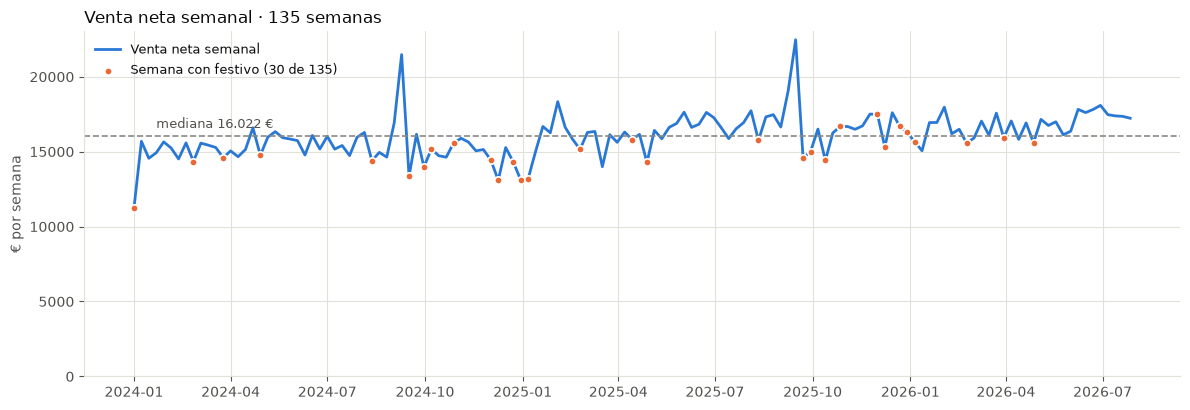


Media de las semanas con festivo ... 14.857,21 €
Media de las semanas sin festivo ... 16.376,52 €
Diferencia ......................... -1.519,31 € (-9,3 %)


In [3]:
# La serie, con las semanas que pierden horas de apertura marcadas.
X_todo = features.construir(serie["periodo_inicio"], festivos)
perdidas = X_todo["horas_cierre_festivo"].to_numpy()
hay = perdidas > 0

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(d, y, color=AZUL, label="Venta neta semanal")
ax.scatter(d[hay], y[hay], s=28, color=NARANJA, zorder=3, edgecolor="white",
           linewidth=1.2, label=f"Semana con festivo ({hay.sum()} de {len(serie)})")
ax.axhline(y.median(), color=GRIS, linestyle="--", linewidth=1.2)
ax.annotate(f"mediana {num(y.median(), 0)} €", xy=(d.iloc[3], y.median()),
            xytext=(0, 6), textcoords="offset points", color=TINTA2, fontsize=9)
ax.set_ylabel("€ por semana")
ax.set_title("Venta neta semanal · 135 semanas", loc="left",
             fontsize=12, color=TINTA)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_ylim(0, None)
fig.tight_layout()
guardar(fig, "serie-y-exposicion")
plt.show()

media_con = y[hay].mean()
media_sin = y[~hay].mean()
print(f"\nMedia de las semanas con festivo ... {num(media_con)} €")
print(f"Media de las semanas sin festivo ... {num(media_sin)} €")
print(f"Diferencia ......................... {num(media_con - media_sin)} € "
      f"({num(100 * (media_con - media_sin) / media_sin, 1)} %)")

Los puntos naranjas caen casi siempre por debajo de la línea. El
festivo se ve a simple vista, y esto es lo que la sección 5 va a
convertir en un coeficiente en euros.
Los dos picos de septiembre (2024 y 2025) son las fiestas
locales, y suben antes de la fiesta. Eso es acopio, y también se mide.

## 2 · Descomposición STL

Antes de modelar, mirar. `STL` separa la serie en **tendencia +
estacionalidad + residuo**.

**Una salvedad sobre el periodo.** `STL` exige un periodo **entero**, así que
se le pasa 52. El real es **52,18** (365,2425 / 7), de modo que la
descomposición se desalinea algo más de un día al año; sobre 2,6 ciclos, unos 3
días. Sirve para leer la forma, no para apoyar en ella una predicción. Por lo
mismo se descartó un SARIMA con `m=52`.

  guardada 03-descomposicion-stl.png / .svg


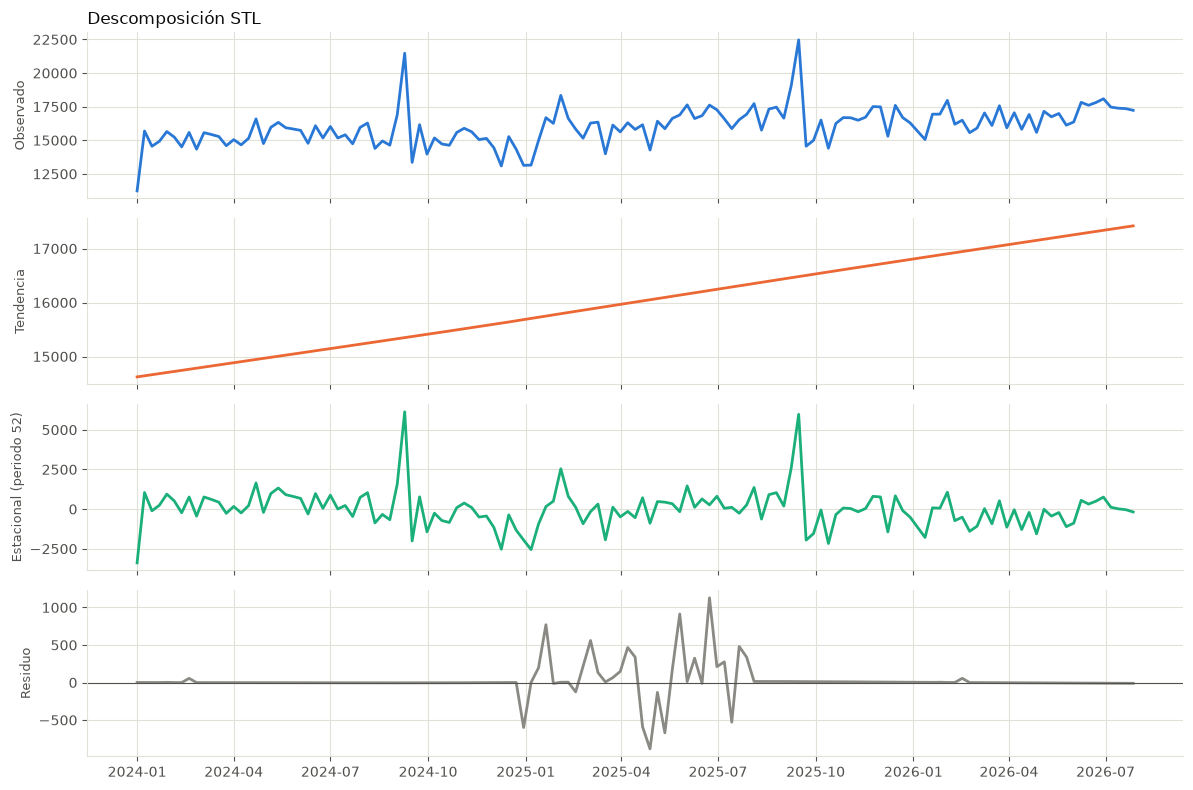

Reparto de la varianza en nuestra serie:
  tendencia ....... 30,9 %
  estacionalidad .. 67,0 %
  residuo ......... 2,1 %

Y esto es lo que STL(period=52) reparte sobre series sin estacionalidad:
  ruido blanco puro              estacionalidad = 70,1 %
  tendencia + ruido, SIN ciclo   estacionalidad = 63,7 %


In [4]:
y_idx = pd.Series(y.to_numpy(), index=pd.DatetimeIndex(d), name="venta")
stl = STL(y_idx, period=52, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
for ax, (comp, etiqueta, color) in zip(axes, [
        (stl.observed, "Observado", AZUL), (stl.trend, "Tendencia", NARANJA),
        (stl.seasonal, "Estacional (periodo 52)", AQUA),
        (stl.resid, "Residuo", GRIS)]):
    ax.plot(comp.index, comp.values, color=color)
    # Etiqueta directa en cada panel: el aqua no llega a 3:1 de contraste, así
    # que ninguna banda se identifica solo por su color.
    ax.set_ylabel(etiqueta, fontsize=9, color=TINTA2)
axes[3].axhline(0, color=TINTA2, linewidth=0.8)
axes[0].set_title("Descomposición STL", loc="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "descomposicion-stl")
plt.show()


def reparto_stl(valores, periodo=52):
    """Qué porcentaje de la varianza se lleva cada componente. Suma 100."""
    f = STL(pd.Series(valores, index=pd.DatetimeIndex(d)[:len(valores)]),
            period=periodo, robust=True).fit()
    v = np.array([np.var(f.trend), np.var(f.seasonal), np.var(f.resid)])
    return 100 * v / v.sum()


t_obs, e_obs, r_obs = reparto_stl(y.to_numpy(float))
print("Reparto de la varianza en nuestra serie:")
print(f"  tendencia ....... {num(t_obs, 1)} %")
print(f"  estacionalidad .. {num(e_obs, 1)} %")
print(f"  residuo ......... {num(r_obs, 1)} %")

# El control: ¿cuánta "estacionalidad" inventa STL sobre series que no la
# tienen?
rng = np.random.default_rng(11)
tt = np.arange(len(y))
controles = {
    "ruido blanco puro": rng.normal(16_000, 1_400, len(y)),
    "tendencia + ruido, SIN ciclo": 15_000 + 17.6 * tt + rng.normal(0, 1_400, len(y)),
}
print("\nY esto es lo que STL(period=52) reparte sobre series sin estacionalidad:")
for nombre, v in controles.items():
    _, e, _ = reparto_stl(v)
    print(f"  {nombre:<30} estacionalidad = {num(e, 1)} %")

El peso estacional de la STL no es evidencia de nada, y es el aviso
de esta sección. Sobre ruido blanco puro STL se inventa ~70 % de
'estacionalidad'; nuestro reparto es indistinguible de ese control.
Con 2,6 repeticiones del ciclo, la componente estacional absorbe el
ruido. El residuo del 2 % no es señal de buen ajuste: es el síntoma.

No dice que el ciclo anual no exista —el tratamiento de la
estacionalidad anual lo midió: lag 52 = +0,365—,
dice que esta descomposición no puede demostrarlo. Lo único que decide
qué modelo usar es la comparación fuera de muestra de la sección 8.

## 3 · El listón, y cómo se mide todo

### Los dos modelos ingenuos de referencia

Predicción **ingenua**: no se estima nada, se copia un valor que ya se conoce.

- **`naive_1`** — la venta de la **semana anterior**. Se repite las 4 semanas
  del horizonte, así que predice una línea plana.
- **`naive_52`** — la venta de la **misma semana del año anterior**. Es el
  ingenuo estacional: no aprende el ciclo, lo copia.

**Un modelo que no gane a los dos no aporta nada**, y decirlo con números es
un resultado válido.

### Validación de origen móvil, y por qué se dice *partición*

El corte entre entrenamiento y prueba se repite **76 veces**: cada partición
entrena con todo lo anterior al corte, predice las 4 semanas siguientes sin
volver a mirar, y se pasa a la siguiente.

**Se dice partición, no pliegue.** Un *pliegue* es cada una de las k partes de
una validación cruzada, donde todas las observaciones rotan entre
entrenamiento y prueba. Aquí no rota nada: el entrenamiento solo crece y nunca
contiene futuro.

**Por qué no basta un corte:** el MAE del `naive_1` va de 212 a 7.349 € según
dónde se parta; la celda de abajo lo mide.

### Las métricas: MAE, RMSE y MAPE

| | Qué mide | Unidad |
|---|---|---|
| **MAE** | Error absoluto medio. **Es la métrica principal** | € |
| **RMSE** | Raíz del error cuadrático medio. Penaliza más los errores grandes | € |
| **MAPE** | El MAE en porcentaje de la venta | % |

**El MAE manda**, y se lee en euros: *«este modelo se equivoca de media en X €
a la semana»*. El **RMSE** dice si el error está repartido o concentrado en
unas pocas semanas malas, y el **MAPE** es el único que se puede comparar con
otra tienda u otro año sin depender de cuánto se facture. Las demás medidas
habituales (ME, MPE, MASE) se calculan igual en `src/modelos.py`, pero no se
imprimen.

In [5]:
# Los cortes de las particiones, en baselines.
origenes = baselines.origenes_particiones(len(y), baselines.HORIZONTE,
                                          n_particiones=len(y))
print(f"{len(origenes)} particiones · entrenan con {origenes.min()}–{origenes.max()} semanas · "
      f"horizonte {baselines.HORIZONTE}")

resultados["baselines"] = modelos.evaluar(serie, ["baselines"])

print("Resumen — lo que va a la memoria")
display(tabla_de(resultados["baselines"]))

print(f"Métricas — mediana sobre las {len(origenes)} particiones")
display(metricas_de(resultados["baselines"]))


mae_n1 = resultados["baselines"].loc[resultados["baselines"]["modelo"] == "naive_1", "mae"]
print(f"naive_1, partición a partición: de {num(mae_n1.min(), 0)} € a {num(mae_n1.max(), 0)} € "
      f"según dónde se parta — por eso no basta un corte")


76 particiones · entrenan con 56–131 semanas · horizonte 4


Resumen — lo que va a la memoria


,mae_mediano,mae_medio,peor_particion,rmse_mediano,particiones,ganados,procedencia
modelo,,,,,,,
naive_1,"790,00","1.087,00","7.349,00","989,00",76,53,listón ingenuo: la semana anterior
naive_52,"1.085,00","1.267,00","3.652,00","1.174,00",76,23,listón ingenuo: la misma semana de la temporad...


Métricas — mediana sobre las 76 particiones


,mae,rmse,mape,particiones
modelo,,,,
naive_1,"790,00","989,00","4,98",76
naive_52,"1.085,00","1.174,00","6,74",76


naive_1, partición a partición: de 212 € a 7.349 € según dónde se parta — por eso no basta un corte


El listón queda en 790 € (naive_1).

1. Sobre una venta típica de 16.022 €, ese listón es un 4,9 % de
error. Cualquier modelo tiene que bajar de ahí, o no ha servido de
nada: si te vas a equivocar lo mismo, mejor usa la regla tonta.

2. El ingenuo estacional es el peor de los dos: 1.085 € frente a
790 €. Copiar la semana de la temporada pasada va peor que
copiar la semana pasada, y eso ya dice algo del ciclo anual antes de
haber modelado nada.

3. Y su MAPE lo confirma: 6,74 % contra 4,98 % del naive_1.
El naive_52 falla porque la tienda crece: la misma semana del año
pasado vendió menos, así que se queda corto de forma sistemática.
No es ruido, es tendencia — y es lo que la sección 5 va a recoger.

4. Peor partición del naive_1: 7.349 €, 9,3 veces su mediana.
Por eso no vale un corte único: de las 76 particiones, según cuál
mires el mismo modelo parece bueno o catastrófico.

## 4 · Suavizado exponencial

De menos a más: cada modelo añade **una ecuación** al anterior, y la pregunta
es si esa ecuación compensa.

| Modelo | Qué añade | Componentes |
|---|---|---|
| **`ses`** | Nada: un **nivel**, ponderando lo reciente por encima de lo antiguo | nivel |
| **`holt`** | **Tendencia** | nivel + pendiente |
| **`holt_winters_52`** | **Estacionalidad** anual (52 índices), aditiva o multiplicativa | nivel + pendiente + 52 índices |

`ses` es la referencia contra la que se compara el modelo elegido en la
sección 8. `holt_winters_52` es el que corresponde en teoría a una serie con
tendencia y estacionalidad, así que hay que probarlo; su resultado está abajo.

*(El alisado doble de Brown se probó también; no gana en ninguna partición.)*

In [6]:
b = metricas_de(resultados["baselines"])
n1, n52 = b.loc["naive_1"], b.loc["naive_52"]
det_b = resultados["baselines"]
peor_n1 = det_b.query("modelo == 'naive_1'")["mae"].max()
n_part = det_b["origen"].nunique()

resultados["suavizado"] = modelos.evaluar(serie, ["suavizado"])

print("Suavizados que ajustan en las 76 particiones (`ses`, `holt`)")
display(metricas_de(resultados["suavizado"]).loc[["ses", "holt"]])

Suavizados que ajustan en las 76 particiones (`ses`, `holt`)


,mae,rmse,mape,particiones
modelo,,,,
ses,"784,00","891,00","4,69",76
holt,"710,00","850,00","4,44",76


`holt` es el mejor suavizado a 4 semanas (710 €).

`ses` (784 €) queda prácticamente empatado con el listón
ingenuo (790 €): a horizonte corto, 'ponderar lo reciente'
es casi 'copiar la semana pasada'. Se lleva a la §8 como listón
declarado — gana la semana típica a 26 semanas, no a 4.

### Holt-Winters no se puede usar en esta serie

Su componente estacional son **52 índices —uno por semana del año— y cada uno
se estima con 2 o 3 observaciones**, porque cada semana del año solo llega una
vez. `statsmodels` ni siquiera arranca sin **dos ciclos anuales completos (104
semanas)**, y las particiones entrenan con menos. La celda mide las dos
consecuencias; es el mismo motivo por el que el ciclo anual pierde en la
sección 5.

1. No ajusta en 48 de 76 particiones (statsmodels exige 104 semanas y no las hay).

2. En las 28 donde sí ajusta, la estacionalidad empeora el error:
732 € frente a 655 € de `holt` (+12 %). El multiplicativo, igual (729 €).

Holt-Winters se descarta con medición. No es el modelo equivocado:
es que 2,6 años no dan para estimar un ciclo de 52 semanas. Se montó,
se corrió y se rompió donde la teoría avisa.

## 5 · Regresión lineal de calendario

Cambia la idea. Los suavizados miran **la venta pasada** y la prolongan; aquí
no se mira la venta: se mira **qué tiene de especial cada semana** y se le
pone un precio en euros.

$$y_t = \beta_0 + \beta_1\,\text{tendencia}_t + \beta_2\,\text{horas cierre festivo}_t + \dots + \varepsilon_t$$

Los diez regresores iniciales son todos **deterministas**: se conocen con años
de antelación. Ninguno es una variable observada de la tienda.

| Regresor | Qué recoge |
|---|---|
| `tendencia` | Las semanas transcurridas. La tienda crece despacio |
| `horas_cierre_festivo` | Horas de apertura que se pierden esa semana por festivo |
| `horas_cierre_festivo_prox1` · `prox2` | Las de **la semana siguiente** y la de después: la gente compra ANTES de la fiesta |
| `pascua_m2` … `pascua_p2` | Cinco semanas alrededor del Domingo de Resurrección, que cambia de fecha cada año |
| `fiesta_local_acopio` | Las 2 semanas previas a la primera fiesta local de septiembre (se mide abajo) |

**El cierre se mide en horas, no con variables de sí/no.** Un festivo en sábado
apenas resta y uno entre semana cierra el día entero; una variable binaria los
mezclaría.

**Se prueban dos versiones**, que solo se diferencian en el ciclo anual:

- **`ols_sin_ciclo`** — sin componente estacional.
- **`ols_spline`** — con un **spline cúbico cíclico** sobre la semana del año.

In [7]:
m = metricas_de(resultados["suavizado"])
liston = metricas_de(resultados["baselines"]).loc["naive_1", "mae"]
mae_ses, mae_holt = m.loc["ses", "mae"], m.loc["holt", "mae"]

det = resultados["suavizado"]
n_total = det["origen"].nunique()
n_falla = int(modelos.fallos_de(det)["particiones_fallidas"].max())

# En las particiones donde sí ajusta, ¿aporta la componente estacional? vs `holt`.
comunes = det.query("modelo == 'holt_winters_52'")["origen"].unique()
jus = metricas_de(det[det["origen"].isin(comunes)])
hw_add = jus.loc["holt_winters_52", "mae"]
hw_mul = jus.loc["holt_winters_52_mul", "mae"]
holt_j = jus.loc["holt", "mae"]

resultados["regresion"] = modelos.evaluar(serie, ["regresion"])

print("Resumen")
display(tabla_de(resultados["regresion"]))

print("Métricas")
display(metricas_de(resultados["regresion"]))


Resumen


,mae_mediano,mae_medio,peor_particion,rmse_mediano,particiones,ganados,procedencia
modelo,,,,,,,
ols_basico,"642,00","644,00","1.335,00","745,00",76,29,el modelo elegido
ols_sin_ciclo,"657,00","676,00","1.422,00","754,00",76,23,"calendario completo, 11 regresores"
ols_spline,"685,00","726,00","1.562,00","784,00",76,24,lineal con spline cíclico


Métricas


,mae,rmse,mape,particiones
modelo,,,,
ols_basico,"642,00","745,00","3,86",76
ols_sin_ciclo,"657,00","754,00","4,06",76
ols_spline,"685,00","784,00","4,14",76


Es el mejor candidato de esta familia, visto hasta aqui.

1. `ols_sin_ciclo` da 657 €: bate al listón de 790 € en un
16,8 %, y también al mejor del suavizado exponencial
(`holt`, 710 €).

2. Sobre una venta típica de 16.022 € es un 4,1 % de error, y en su
peor partición de 76 llega a 1.422 € (8,9 %).

A 4 semanas es más alto que a 26, y no es un
empeoramiento del modelo. A 26 semanas una semana catastrófica se
promedia con otras 25; a 4 es la cuarta parte de lo que se mide, y
sale entera. Es aritmética del horizonte, no del ajuste.

3. El ciclo anual sigue haciendo daño: `ols_spline` da 685 €, peor
que no ponerlo (657 €). Con 2,6 repeticiones no hay con qué
aprender un ciclo de 52 semanas — el mismo motivo por el que
Holt-Winters no ajustaba. Dos vías independientes dicen lo mismo.
(En peor caso sí gana el spline: 1.562 € contra 1.422 €.)

### El modelo por dentro: qué vale cada cosa, en euros

Es la ventaja que ningún otro modelo del notebook tiene. `ses` predice un
número y no se sabe de dónde sale; aquí **cada regresor lleva un precio**, y
ese precio se le puede explicar a la tienda.

*(Ajustado sobre las 135 semanas, con los diez regresores iniciales. Más abajo
se comprueba si los no significativos aportan algo fuera de muestra, y el
modelo se recorta según ese resultado.)*

In [8]:
a = metricas_de(resultados["regresion"])
liston = metricas_de(resultados["baselines"]).loc["naive_1", "mae"]
mejor_suavizado = metricas_de(resultados["suavizado"]).query("particiones == particiones.max()")["mae"].min()
nombre_suavizado = metricas_de(resultados["suavizado"]).query("particiones == particiones.max()")["mae"].idxmin()
t_regresion = tabla_de(resultados["regresion"])
sin_c, con_c = a.loc["ols_sin_ciclo"], a.loc["ols_spline"]
peor_sin = t_regresion.loc["ols_sin_ciclo", "peor_particion"]
peor_spl = t_regresion.loc["ols_spline", "peor_particion"]

# Ajuste sobre la serie entera, solo para leer los coeficientes. La evaluacion
# que cuenta es la de arriba, en las 76 particiones; esto no la sustituye.
X_ols = modelos.matrices(serie)["ninguna"]
ajuste = sm.OLS(y.to_numpy(float), sm.add_constant(X_ols.to_numpy(float))).fit()

coef = pd.DataFrame({
    "coeficiente": ajuste.params,
    "error_est": ajuste.bse,
    "p_valor": ajuste.pvalues,
}, index=["constante"] + list(X_ols.columns))
coef["significativo"] = np.where(coef["p_valor"] < 0.05, "sí", "no")
display(coef.round({"coeficiente": 1, "error_est": 1, "p_valor": 4}))

print(f"R² = {num(ajuste.rsquared, 3)} · desviación del residuo = {num(np.std(ajuste.resid), 0)} €")
print(f"Venta típica de una semana sin festivos = {num(ajuste.params[0], 0)} € (la constante)")


,coeficiente,error_est,p_valor,significativo
constante,"15.079,50","151,80","0,00",sí
tendencia,"17,10","1,80","0,00",sí
horas_cierre_festivo,"-203,90","23,60","0,00",sí
horas_cierre_festivo_prox1,"46,20","25,10","0,07",no
horas_cierre_festivo_prox2,"-32,30","25,60","0,21",no
pascua_m2,"-59,40","551,90","0,91",no
pascua_m1,"-352,00","546,80","0,52",no
pascua_p0,"1.777,40","533,90","0,00",sí
pascua_p1,"-255,60","474,30","0,59",no
pascua_p2,"-685,20","474,20","0,15",no


R² = 0,699 · desviación del residuo = 771 €
Venta típica de una semana sin festivos = 15.079 € (la constante)


Lo que este modelo le puede contar a la tienda.

1. Cada hora de cierre cuesta 204 €. Un festivo entre semana que
cierra el día entero son ~6,4 horas, o sea unos
1.311 € de venta que no se hacen esa semana.

2. Y hay acopio: la semana anterior a un festivo vende 46 € más
por cada hora que se va a cerrar. La gente no deja de comprar, compra
antes. Por eso el regresor mira hacia adelante y no solo al presente.

3. La tienda crece 17,1 € por semana, unos 891 € al año.
Es la única cifra del modelo que no depende del calendario.

4. Cada una de las dos semanas previas a la primera fiesta local vende 3.861 €
más de lo que explica el resto del calendario. Es fiesta del pueblo,
no solo el lunes cerrado — y era el mayor agujero del modelo (§5, abajo).

5. Con ese término, explica el 69,9 % de la variación. Lo que queda
fuera son picos sueltos, ya sin un patrón de calendario claro.

### El término de aprovisionamiento de las fiestas locales

El mayor error de un modelo de solo calendario está en **septiembre**: la
semana previa a las fiestas locales la venta sube unos **3.900 €** por encima
de lo que explican las horas de cierre (la celda de abajo lo mide). No es
*«cierra el lunes»*, que ya lo recoge `horas_cierre_festivo`, sino **la fiesta
del pueblo**: comidas familiares, gente de fuera.

Por eso el modelo lleva un regresor más, `fiesta_local_acopio`: un indicador de
las **2 semanas previas a la primera fiesta local del año**. Se estima sobre
**solo 4 semanas (dos septiembres)**, así que la evidencia de ese coeficiente es
limitada, y se declara. La celda mide qué aporta quitándolo
(`ols_sin_acopio`).

In [9]:
hora = coef.loc["horas_cierre_festivo", "coeficiente"]
tend = coef.loc["tendencia", "coeficiente"]
prox1 = coef.loc["horas_cierre_festivo_prox1", "coeficiente"]
horas_dia = features.HORAS_SEMANA_COMPLETA / 7

ac = coef.loc["fiesta_local_acopio", "coeficiente"]

comp = modelos.evaluar(serie, ["ols_sin_ciclo", "ols_sin_acopio"])
print("Con y sin el término de acopio, en las mismas 76 particiones (h=4):")
display(tabla_de(comp)[["mae_mediano", "mae_medio", "peor_particion", "particiones"]])

# Coeficiente y R² con y sin el término, sobre las 135 semanas.
coef_ac = coef.loc["fiesta_local_acopio", "coeficiente"]
aj_sin = sm.OLS(y.to_numpy(float),
                sm.add_constant(modelos.matrices(serie)["sin_acopio"],
                                has_constant="add")).fit()
t = tabla_de(comp)
sube = t.loc["ols_sin_ciclo", "mae_mediano"] - t.loc["ols_sin_acopio", "mae_mediano"]

Con y sin el término de acopio, en las mismas 76 particiones (h=4):


,mae_mediano,mae_medio,peor_particion,particiones
modelo,,,,
ols_sin_acopio,"639,00","733,00","2.455,00",76
ols_sin_ciclo,"657,00","676,00","1.422,00",76


No cambia la semana típica, pero recorta el reventón de septiembre.

1. MAE mediano 639 → 657 € (+18 €), pero la peor
partición baja de 2.455 a 1.422 €, y el R² sube de 0,499 a 0,699.

2. El coeficiente es +3.861 €: la semana de acopio vende eso
por encima de lo que explica el resto del calendario.

3. Ajustado sobre 4 semanas. En las particiones cuyo test cae en
septiembre de 2025, el término —estimado solo con 2024— ya reduce el
error (cifras en el backtest del §11): comprobación fuera de muestra, aunque fina.

### ¿Aportan algo las 6 variables no significativas?

La tabla de coeficientes deja **5 de los 11 términos significativos al 5 %**:
la constante, la tendencia, las horas de cierre en festivo, la semana de Semana
Santa y el aprovisionamiento de las fiestas locales. Los otros 6 —las dos
semanas de proximidad a festivo y cuatro de los cinco términos de Pascua— no lo
son. Pero eso se apoya en el **p-valor de un único ajuste**, no en la prueba
fuera de muestra que decide el resto del notebook.

`ols_basico` es el modelo con **solo las 5 variables significativas**,
evaluado en las mismas 76 particiones. Si da igual o mejor que el modelo
completo, las 6 variables no significativas tampoco ayudan juntas.

In [10]:
comp_basico = modelos.evaluar(serie, ["ols_sin_ciclo", "ols_basico"])
resultados["basico"] = comp_basico[comp_basico["modelo"] == "ols_basico"]
print("Modelo completo (11 regresores) frente al básico (5 significativos), en las mismas 76 particiones (h=4):")
display(tabla_de(comp_basico)[["mae_mediano", "mae_medio", "peor_particion", "particiones"]])

aj_basico = sm.OLS(y.to_numpy(float),
                   sm.add_constant(modelos.matrices(serie)["basico"],
                                   has_constant="add")).fit()
t_b = tabla_de(comp_basico)
dif = t_b.loc["ols_sin_ciclo", "mae_mediano"] - t_b.loc["ols_basico", "mae_mediano"]

Modelo completo (11 regresores) frente al básico (5 significativos), en las mismas 76 particiones (h=4):


,mae_mediano,mae_medio,peor_particion,particiones
modelo,,,,
ols_basico,"642,00","644,00","1.335,00",76
ols_sin_ciclo,"657,00","676,00","1.422,00",76


Las 6 variables no significativas no aportan, ni juntas.

1. MAE mediano: 642 € (básico) frente a 657 € (completo) -> el básico es 15 € mejor.

2. Peor partición: 1.335 € (básico) frente a 1.422 € (completo).

3. R² (135 semanas): 0,678 (básico, 5 parámetros) frente a 0,699 (completo, 11 parámetros).
R² ajustado: 0,669 frente a 0,675 -> casi igual: el R² más alto del completo es solo por tener más parámetros.

4. BIC: 2.211,6 (básico) frente a 2.232,0 (completo) -> el BIC penaliza la complejidad y favorece al modelo con menos variables.

Las 5 variables básicas bastan para la capacidad predictiva medida fuera de muestra.
Las otras 6 no la mejoran, ni juntas ni por separado -> se retiran del modelo elegido
Su respaldo era solo teórico, no precisión medida.

### Decisión: el modelo elegido es `ols_basico`

El modelo con solo las 5 variables significativas **no pierde precisión fuera
de muestra: gana en los dos criterios que deciden** (MAE mediano y peor
partición), con R² ajustado prácticamente empatado y el BIC a favor del
básico. Las 6 variables que se quitan solo tenían respaldo teórico, nunca
precisión medida.

**Desde aquí, `ols_basico` es «el modelo» en el resto del notebook.**
`ols_sin_ciclo` se conserva como comparación en la tabla de la sección 8.

In [11]:
# Diagnostico adicional que no cabia en la ablacion de arriba: AIC/BIC, y el
# aporte del acopio dentro del modelo basico (no solo del completo).
r2_completo, aic_completo, bic_completo = ajuste.rsquared, ajuste.aic, ajuste.bic

# --- Desde aqui, ajuste/coef/X_ols son los del modelo elegido (ols_basico) ---
X_ols = modelos.matrices(serie)["basico"]
ajuste = sm.OLS(y.to_numpy(float), sm.add_constant(X_ols.to_numpy(float))).fit()

print(f"AIC básico {num(ajuste.aic, 1)} frente a completo {num(aic_completo, 1)}")
print(f"BIC básico {num(ajuste.bic, 1)} frente a completo {num(bic_completo, 1)}")

comp_acopio_basico = modelos.evaluar(serie, ["ols_basico", "ols_basico_sin_acopio"])
print()
print("El acopio, dentro del modelo básico (no solo del completo, más arriba):")
display(tabla_de(comp_acopio_basico)[["mae_mediano", "peor_particion", "particiones"]])

coef = pd.DataFrame({
    "coeficiente": ajuste.params,
    "error_est": ajuste.bse,
    "p_valor": ajuste.pvalues,
}, index=["constante"] + list(X_ols.columns))
coef["significativo"] = np.where(coef["p_valor"] < 0.05, "sí", "no")

print()
print("=" * 70)
print("El modelo elegido, recortado a las 5 variables significativas")
print("=" * 70)
display(coef.round({"coeficiente": 1, "error_est": 1, "p_valor": 4}))
print(f"R² = {num(ajuste.rsquared, 3)} · desviación del residuo = {num(np.std(ajuste.resid), 0)} €")

hora = coef.loc["horas_cierre_festivo", "coeficiente"]
tend = coef.loc["tendencia", "coeficiente"]
ac = coef.loc["fiesta_local_acopio", "coeficiente"]
pascua = coef.loc["pascua_p0", "coeficiente"]
horas_dia = features.HORAS_SEMANA_COMPLETA / 7

AIC básico 2.197,0 frente a completo 2.200,0
BIC básico 2.211,6 frente a completo 2.232,0



El acopio, dentro del modelo básico (no solo del completo, más arriba):


,mae_mediano,peor_particion,particiones
modelo,,,
ols_basico,"642,00","1.335,00",76
ols_basico_sin_acopio,"687,00","2.175,00",76



El modelo elegido, recortado a las 5 variables significativas


,coeficiente,error_est,p_valor,significativo
constante,"15.069,30","146,00","0,00",sí
tendencia,"17,20","1,80","0,00",sí
horas_cierre_festivo,"-203,00","23,30","0,00",sí
pascua_p0,"1.688,20","534,50","0,00",sí
fiesta_local_acopio,"3.846,30","414,00","0,00",sí


R² = 0,678 · desviación del residuo = 797 €


Lo que este modelo le puede contar a la tienda (5 variables, todas significativas).

1. Cada hora de cierre cuesta 203 €. Un festivo entre semana que
cierra el día entero son ~6,4 horas, o sea unos
1.305 € de venta que no se hacen esa semana.

2. La tienda crece 17,2 € por semana, unos 893 € al año.
Es la única cifra del modelo que no depende del calendario.

3. La semana de Semana Santa vende 1.688 € más de lo normal.
Las cuatro semanas de alrededor (2 y 1 antes, 1 y 2 después) no se
distinguían de cero y no mejoraban la predicción fuera de muestra: se
quitaron del modelo, aunque la Semana Santa se sigue vigilando entera
por si algún año se mueve el patrón.

4. Cada una de las dos semanas previas a la primera fiesta local vende 3.846 €
más de lo que explica el resto del calendario. Es fiesta del pueblo,
no solo el lunes cerrado.

5. Con estas 5 variables, explica el 67,8 % de la variación —
frente al 69,9 % de las 11— con menos de la mitad de los parámetros.

## 6 · ARIMA con regresores externos

La sección 5 metió el calendario en una **regresión**: cada semana se explica
por sus regresores, y se da por hecho que lo que queda —el residuo— es ruido
sin memoria. **ARIMA pone a prueba esa suposición.** Si una semana alta todavía
arrastra a la siguiente después de descontar el calendario, un término
temporal lo recoge y la predicción mejora; si el residuo ya es ruido, solo
añade parámetros que estimar con pocos datos.

Un modelo **ARIMA(p, d, q)** tiene tres piezas:

| Pieza | Qué añade |
|---|---|
| **p** — AR | Cuántos **valores pasados de la serie** entran en la ecuación |
| **d** — I | Cuántas veces se **diferencia** (restar la semana anterior) para quitar tendencia o raíz unitaria |
| **q** — MA | Cuántos **errores de predicción pasados** entran |

Los regresores (el `exog=` de `statsmodels`) meten **el mismo calendario de la
sección 5 dentro del marco ARIMA**, en lugar de dejarlo en una regresión con
errores independientes.

Se prueban **tres órdenes**, ninguno con parte estacional:

- **`arima_xreg_011`** — `d=1`, `q=1`: diferencia y modela el error. Al
  diferenciar, la tendencia pasa a ser una constante, así que se saca de los
  regresores.
- **`arima_xreg_100`** — `d=0`, `p=1`: un término autorregresivo sobre el nivel.
- **`arima_xreg_101`** — `d=0`, `p=1`, `q=1`.

In [12]:
# ARIMA con xreg, en las mismas 76 particiones y el mismo horizonte (h=4) que
# todo lo demás. Tarda ~80 s: ajusta un modelo de espacio de estados por corte.
resultados["arima"] = modelos.evaluar(serie, ["arima"])

comparar = pd.concat([
    resultados["arima"],
    resultados["basico"],
    resultados["suavizado"].query("modelo == 'ses'"),
    resultados["baselines"].query("modelo == 'naive_1'"),
], ignore_index=True)

print("Resumen — los tres ARIMA frente al modelo elegido, a `ses` y al listón")
display(tabla_de(comparar))

print("Métricas")
display(metricas_de(comparar))

Resumen — los tres ARIMA frente al modelo elegido, a `ses` y al listón


,mae_mediano,mae_medio,peor_particion,rmse_mediano,particiones,ganados,procedencia
modelo,,,,,,,
ols_basico,"642,00","644,00","1.335,00","745,00",76,17,el modelo elegido
arima_xreg_011,"642,00","697,00","1.555,00","734,00",76,16,arima() con xreg
arima_xreg_100,"654,00","706,00","2.982,00","752,00",76,14,arima() con xreg
arima_xreg_101,"698,00","700,00","1.453,00","815,00",76,10,arima() con xreg
ses,"784,00","938,00","3.356,00","891,00",76,8,suavizado exponencial simple
naive_1,"790,00","1.087,00","7.349,00","989,00",76,11,listón ingenuo: la semana anterior


Métricas


,mae,rmse,mape,particiones
modelo,,,,
ols_basico,"642,00","745,00","3,86",76
arima_xreg_011,"642,00","734,00","3,87",76
arima_xreg_100,"654,00","752,00","4,02",76
arima_xreg_101,"698,00","815,00","4,22",76
ses,"784,00","891,00","4,69",76
naive_1,"790,00","989,00","4,98",76


In [13]:
mt = modelos.metricas(comparar)   # sin redondear: empatan al euro
tt = tabla_de(comparar)
ordenes = ["arima_xreg_011", "arima_xreg_100", "arima_xreg_101"]
mejor = mt.loc[ordenes, "mae"].idxmin()
mae_best = mt.loc[mejor, "mae"]
mae_ols = mt.loc["ols_basico", "mae"]
mae_ses = mt.loc["ses", "mae"]
liston = mt.loc["naive_1", "mae"]
peor_best = tt.loc[mejor, "peor_particion"]
peor_ols = tt.loc["ols_basico", "peor_particion"]
d0 = ["arima_xreg_100", "arima_xreg_101"]
peor_d0 = tt.loc[d0, "peor_particion"].max()
mae_d0 = mt.loc[d0, "mae"].min()

peores5 = resultados["arima"].query("modelo == @mejor").nlargest(5, "mae")["origen"].to_numpy()
f5 = pd.to_datetime(serie["periodo_inicio"]).iloc[peores5]
todas_sep25 = bool(((f5.dt.year == 2025) & f5.dt.month.isin([8, 9])).all())

assert mae_best > mae_ols, "algún ARIMA ya gana al modelo elegido"

ARIMA no mejora al modelo de calendario: empata en la semana típica
y pierde en el peor caso.

1. El mejor de los tres, `arima_xreg_011`, da 641,66 €, frente a los
641,51 € del modelo elegido: con los mismos 5 regresores, empata
(diferencia de 0,15 €). Bate al listón (790 €) y a `ses`
(784 €), pero sus términos AR y MA no compran precisión.

2. Y su peor partición es 1.555 €, frente a los 1.335 € de
`ols_basico`. El término de error ARMA amplifica
los picos de calendario en vez de corregirlos.

3. Los dos `d=0` se quedan en 654 € el mejor de ellos, por encima
del modelo elegido, y su peor partición llega a 2.982 €.
(Con los 11 regresores del modelo completo quedaban mal especificados,
con el AR pegado a 1; con los 5 eso desaparece.)

La familia `arima()` con `xreg` se descarta
con medición. El motivo de fondo —que no queda estructura temporal en el
residuo del modelo— se comprueba en el apartado siguiente.

### El residuo del modelo, comprobado

Lo anterior se apoya en que **el residuo no deja estructura temporal que un
ARIMA pueda aprovechar**. Aquí se comprueba:

- **Gráfico de autocorrelación (ACF).** Si el residuo tuviera memoria, las
  barras saldrían de la banda.
- **Contraste de Ljung-Box.** H₀: sin autocorrelación hasta el retardo *k*. Se
  busca **p > 0,05**.
- **Dickey-Fuller aumentado (ADF).** H₀: hay raíz unitaria. Se busca
  **p < 0,05**.

Se mira sobre el modelo elegido (`ols_basico`) y sobre su versión sin el
término de aprovisionamiento, porque ese indicador —1 en solo 4 semanas— deja
huella en el contraste.

  guardada 03-residuo-acf.png / .svg


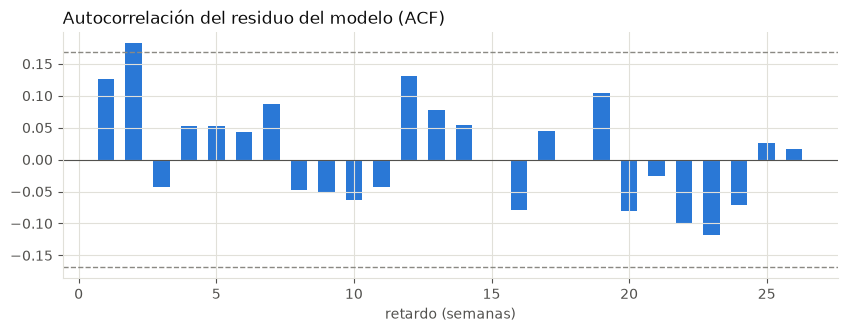

 retardo    Ljung-Box p · modelo    · sin acopio
       2                   0,033           0,070
       4                   0,113           0,203
       8                   0,297           0,569
      12                   0,343           0,692
      26                   0,582           0,653

ADF (H0: raíz unitaria):  p = 0,0000   ·   ρ1 del residuo = +0,128


In [14]:
def residuo(base):
    X = modelos.matrices(serie)[base]
    return pd.Series(sm.OLS(y.to_numpy(float),
                            sm.add_constant(X, has_constant="add")).fit().resid,
                     index=pd.DatetimeIndex(d))

res = residuo("basico")           # el modelo elegido
res_sin = residuo("basico_sin_acopio")  # sin el término de acopio

fig, ax = plt.subplots(figsize=(10, 3.2))
lags = np.arange(1, 27)
ax.bar(lags, acf(res, nlags=26, fft=False)[1:], width=0.6, color=AZUL)
b = 1.96 / np.sqrt(len(res))
for s in (b, -b):
    ax.axhline(s, color=GRIS, ls="--", lw=1)
ax.axhline(0, color=TINTA2, lw=0.8)
ax.set_title("Autocorrelación del residuo del modelo (ACF)",
             loc="left", fontsize=12, color=TINTA)
ax.set_xlabel("retardo (semanas)")
guardar(fig, "residuo-acf")
plt.show()

print(f"{'retardo':>8}  {'Ljung-Box p · modelo':>22}  {'· sin acopio':>14}")
for k in (2, 4, 8, 12, 26):
    p_mod = acorr_ljungbox(res, lags=[k], return_df=True)["lb_pvalue"].iloc[0]
    p_sin = acorr_ljungbox(res_sin, lags=[k], return_df=True)["lb_pvalue"].iloc[0]
    print(f"{k:>8}  {num(p_mod, 3):>22}  {num(p_sin, 3):>14}")

adf_p = adfuller(res, autolag="AIC")[1]
print(f"\nADF (H0: raíz unitaria):  p = {num(adf_p, 4)}   ·   "
      f"ρ1 del residuo = {num(res.autocorr(1), 3, signo=True)}")

Queda un resto de estructura a retardo corto, pero no es aprovechable.

1. ADF: el residuo es estacionario (p < 0,001). No hay raíz unitaria.

2. Ljung-Box: sin el término de acopio el residuo es limpio (p > 0,20 de
retardo 4 en adelante). Con el término aparece una p baja a retardo 2
(0,033; desde el 4 ya es 0,113): es el efecto de un indicador que vale
1 en 4 semanas, dos de ellas consecutivas — no es memoria de la serie.

3. Y aunque hubiera memoria, no se aprovecha: los ARIMA del §6 —que
existen para modelar esa persistencia— no mejoran el pronóstico y en
las semanas malas lo empeoran.

4. Por meses, el término de acopio hizo su trabajo: septiembre pasa de
+1.285 € de residuo medio a -160 €. Ya no es el atípico;
el mayor ahora es ago (+398 €), y ningún mes se dispara.

### La metodología Box-Jenkins, paso a paso

Box-Jenkins da **ocho pasos** para llegar a un ARIMA. Los de la sección 6 se
eligieron a mano y se compararon por su error; aquí se hacen los que faltaban,
**la identificación (5) y el diagnóstico de cada modelo (7)**, y se reúnen los
demás:

| Paso | Herramienta | Dónde está |
|---|---|---|
| 1 · Lectura de datos | — | Sección 1 |
| 2 · Representación gráfica | — | Sección 1 |
| 3 · ¿Hace falta transformar? | Box-Cox | **aquí** |
| 4 · Contraste de estacionariedad | Dickey-Fuller aumentado | **aquí** |
| 5 · **Identificar la estructura ARMA** | ACF y PACF | **aquí** |
| 6 · Estimación | ARIMA | Sección 6 |
| 7 · **Diagnóstico y elección del modelo** | Ljung-Box | **aquí** (la elección, en las secciones 6 y 8) |
| 8 · Predicción | — | Sección 11 |

**Dos adaptaciones a datos semanales:**

- **Paso 3.** Para comparar media y desviación típica se agrupa por **meses con
  4 semanas o más**.
- **Paso 5.** El paso 4 muestra que la serie es estacionaria **en torno a una
  tendencia**, así que no se diferencia: se identifica sobre la serie **sin su
  tendencia lineal**, y además sobre el **residuo del modelo de calendario**,
  que es lo que la parte ARMA tendría que explicar. Se mira la parte regular y
  la estacional, hasta el **retardo 60**, pasando por el 52.

Los ARIMA se ajustan con hasta 1.000 iteraciones para asegurar que convergen:
con el límite por defecto de 50, varios no llegaban a hacerlo.

In [15]:
mes = {1: "ene", 2: "feb", 3: "mar", 4: "abr", 5: "may", 6: "jun",
       7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov", 12: "dic"}
pm = res.groupby(res.index.month).mean()
pm_sin = res_sin.groupby(res_sin.index.month).mean()
peor_mes = pm.abs().idxmax()
p_lb2, p_lb4 = acorr_ljungbox(res, lags=[2, 4], return_df=True)["lb_pvalue"]

bj = modelos.box_jenkins(serie)

lam = 1 - bj["boxcox_pendiente"]
print("Paso 3 · ¿Hace falta transformar? (log de la desviación sobre log de la media)")
print(f"  log(desv. típica) sobre log(media), {bj['boxcox_meses']} meses: "
      f"pendiente {num(bj['boxcox_pendiente'], 3)}, correlación {num(bj['boxcox_r'], 3)}")

Paso 3 · ¿Hace falta transformar? (log de la desviación sobre log de la media)
  log(desv. típica) sobre log(media), 31 meses: pendiente -1,295, correlación -0,105


La correlación es casi nula: no hay relación entre nivel y dispersión,
así que la pendiente no se interpreta como 1 − λ y no se transforma (λ = 1).

Contraste de estacionariedad (ADF con tendencia): ADF = -10,415, p = 3,2e-16.
Se rechaza la raíz unitaria: la serie es estacionaria en torno a una
tendencia. No hay que diferenciar (d = 0).

  guardada 03-box-jenkins-identificacion.png / .svg


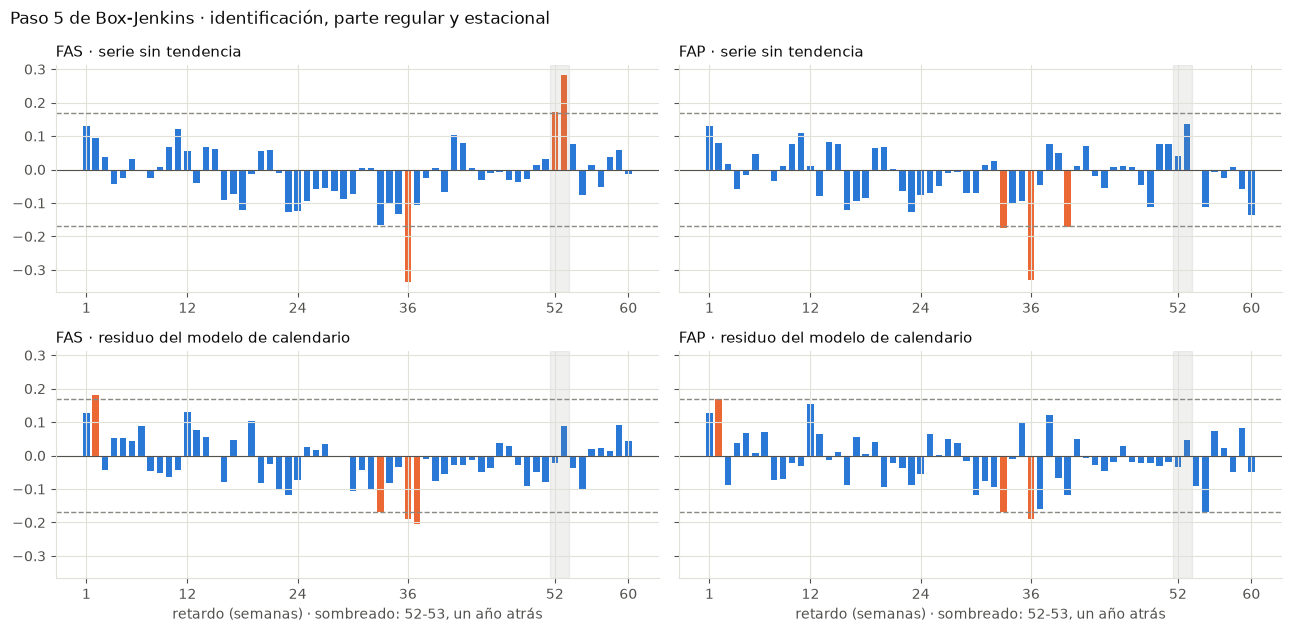

Banda de ruido (±1,96/√n, la que dibuja acf() en R): ±0,169
Retardos fuera de banda:
  serie sin tendencia · FAS:  1-12 → ninguno      13-60 → 36, 52, 53
  serie sin tendencia · FAP:  1-12 → ninguno      13-60 → 33, 36, 40
  residuo del modelo  · FAS:  1-12 → 2            13-60 → 33, 36, 37
  residuo del modelo  · FAP:  1-12 → 2            13-60 → 33, 36


In [16]:
ident = bj["identificacion"]
banda = bj["banda"]

fig, ejes = plt.subplots(2, 2, figsize=(13, 6.4), sharey=True)
paneles = [("fas_sin_tendencia", "FAS · serie sin tendencia"),
           ("fap_sin_tendencia", "FAP · serie sin tendencia"),
           ("fas_residuo", "FAS · residuo del modelo de calendario"),
           ("fap_residuo", "FAP · residuo del modelo de calendario")]
for ax, (col, titulo) in zip(ejes.ravel(), paneles):
    fuera = ident[col].abs() > banda
    ax.bar(ident.index, ident[col], width=0.7,
           color=[NARANJA if f else AZUL for f in fuera])
    for s in (banda, -banda):
        ax.axhline(s, color=GRIS, ls="--", lw=1)
    ax.axhline(0, color=TINTA2, lw=0.8)
    ax.axvspan(51.5, 53.5, color=GRIS, alpha=0.12)   # un año atrás: la parte estacional
    ax.set_title(titulo, loc="left", fontsize=11, color=TINTA)
    ax.set_xticks([1, 12, 24, 36, 52, 60])
for ax in ejes[1]:
    ax.set_xlabel("retardo (semanas) · sombreado: 52-53, un año atrás")
fig.suptitle("Paso 5 de Box-Jenkins · identificación, parte regular y estacional",
             x=0.01, ha="left", fontsize=12, color=TINTA)
fig.tight_layout()
guardar(fig, "box-jenkins-identificacion")
plt.show()

def fuera_de_banda(col, desde=1, hasta=60):
    t = ident.loc[desde:hasta, col]
    f = t.index[t.abs() > banda].tolist()
    return ", ".join(str(r) for r in f) if f else "ninguno"

print(f"Banda de ruido (±1,96/√n, la que dibuja acf() en R): ±{num(banda, 3)}")
print("Retardos fuera de banda:")
for col, nombre in [("fas_sin_tendencia", "serie sin tendencia · FAS"),
                    ("fap_sin_tendencia", "serie sin tendencia · FAP"),
                    ("fas_residuo", "residuo del modelo  · FAS"),
                    ("fap_residuo", "residuo del modelo  · FAP")]:
    print(f"  {nombre}:  1-12 → {fuera_de_banda(col, 1, 12):10s}   13-60 → {fuera_de_banda(col, 13, 60)}")

In [17]:
st, re_ = ident["fas_sin_tendencia"], ident["fas_residuo"]
max_reg = ident.loc[1:12, ["fas_sin_tendencia", "fap_sin_tendencia"]].abs().max().max()
lb52 = bj["ljung_box_residuo"][52]
# Lo que el texto de abajo afirma, comprobado: si cambia el dato, que falle aquí.
assert max_reg < banda, "la serie sin tendencia tiene retardos cortos fuera de banda"
assert max(abs(st[52]), abs(st[53])) > banda, "ya no hay autocorrelación anual en la serie"
assert max(abs(re_[52]), abs(re_[53])) < banda and lb52 > 0.05, "el residuo conserva la parte anual"
esperados = 0.05 * 60

print()
m_regresion = metricas_de(resultados["regresion"])["mae"]
assert m_regresion["ols_spline"] > m_regresion["ols_basico"], "el ciclo anual ya mejora la predicción"

3. Lo que sale de la banda en el residuo:
fas 2, 33, 36, 37; fap 2, 33, 36.
- El del retardo 2 es el término de acopio —vale 1 en cuatro semanas, dos
a dos consecutivas—, no memoria de la venta.
- Los de 33 a 37 semanas (unos 8 meses) son negativos y van juntos, así
que no se despachan como azar, aunque con 60 retardos caigan fuera unos
3 por casualidad. Los pares de semanas que más pesan enfrentan enero
(semanas bajas) con septiembre (altas): es un resto débil de la forma
del año que el calendario no recoge. Ese resto ya se intentó modelar con
el ciclo anual del §5 (spline) y predice peor (685 € frente a
642 €): con 2,6 años no se aprende. Y no cae en retardos estacionales
(52), así que tampoco lo recogería la parte estacional de un ARIMA.

4. Conclusión del paso 5: ARMA(0,0) sin parte estacional sobre el residuo;
lo que queda no lo aprovecha ningún término AR, MA ni estacional.
Un ARIMA(0,0,0) con el calendario como xreg es la regresión de calendario
del §5. Box-Jenkins, seguido desde el principio, lleva al modelo elegido.

Identificación: no queda estructura ARMA una vez metido el calendario.

1. Parte regular (retardos 1-12). En la serie sin tendencia ni la fas ni la
fap salen de la banda (la mayor, 0,129, frente a ±0,169).
No hay estructura AR ni MA de corto plazo.

2. Parte estacional (un año atrás, retardos 52-53). La serie sin tendencia
sí se parece a sí misma un año antes: fas 0,170 y 0,282. Es el ciclo
anual que ya había medido la estacionalidad anual. Pero en el residuo del modelo de
calendario desaparece: fas -0,023 y 0,089, y Ljung-Box conjunto hasta el
retardo 52 no rechaza (p = 0,303). El patrón anual son las fiestas del
pueblo y la Semana Santa, que se repiten cada año y el modelo ya incluye.
No hace falta parte estacional en el ARIMA.

,orden,converge,ljung_box_p_4,ljung_box_p_8,ljung_box_p_12,ljung_box_p_24,ljung_box_p_52
modelo,,,,,,,
arima_xreg_100,"(1, 0, 0)",True,"0,12","0,35","0,40","0,57","0,67"
arima_xreg_101,"(1, 0, 1)",True,"0,34","0,71","0,71","0,76","0,88"
arima_xreg_011,"(0, 1, 1)",True,"0,14","0,37","0,41","0,66","0,91"


  guardada 03-box-jenkins-diagnostico.png / .svg


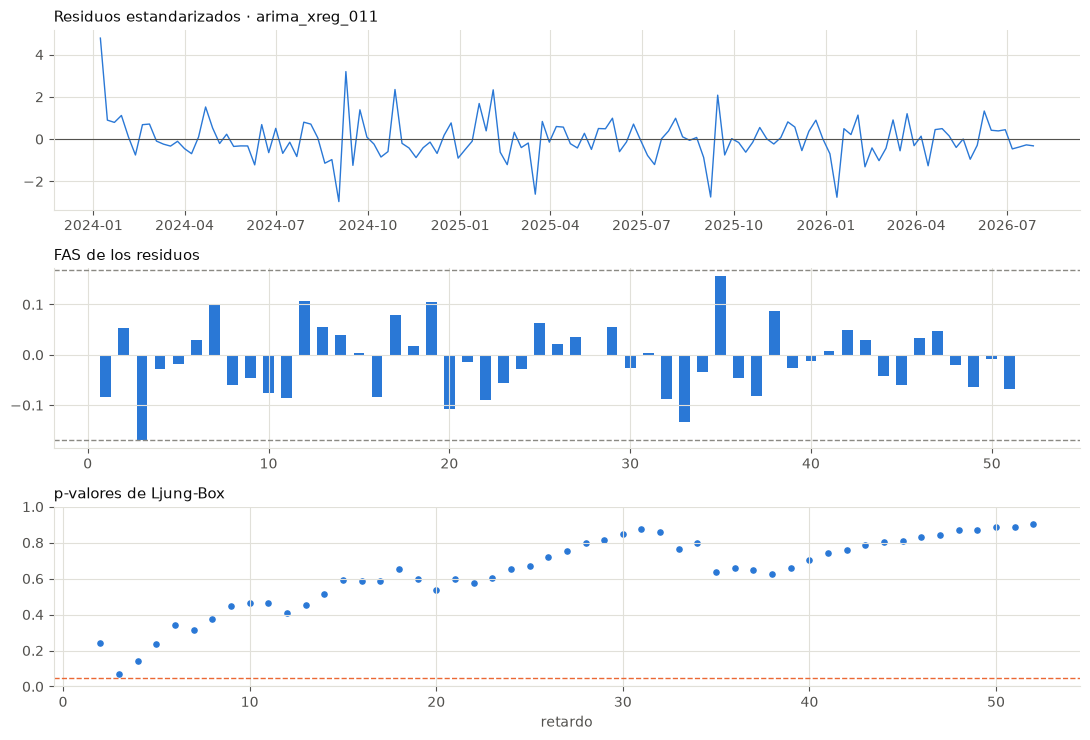

In [18]:
diag = bj["diagnostico"].copy()
display(diag.round(3))

# El gráfico de tsdiag() de R, para el ARIMA que mejor predice en el §6:
# residuos estandarizados, FAS de los residuos y p-valores de Ljung-Box, hasta
# el retardo 52 para cubrir también la parte estacional.
from statsmodels.stats.diagnostic import acorr_ljungbox as _lb
aj = bj["ajustes"]["arima_xreg_011"]
r = pd.Series(np.asarray(aj.resid)[1:])
r_std = (r - r.mean()) / r.std()
fig, (a1, a2, a3) = plt.subplots(3, 1, figsize=(11, 7.5))
a1.plot(d.iloc[1:].to_numpy(), r_std, color=AZUL, lw=1)
a1.axhline(0, color=TINTA2, lw=0.8)
a1.set_title("Residuos estandarizados · arima_xreg_011", loc="left", fontsize=11)
fas_r = acf(r, nlags=52)[1:]
a2.bar(range(1, 53), fas_r, width=0.6, color=AZUL)
for s in (bj["banda"], -bj["banda"]):
    a2.axhline(s, color=GRIS, ls="--", lw=1)
a2.set_title("FAS de los residuos", loc="left", fontsize=11)
p_lb = _lb(r, lags=list(range(2, 53)), model_df=1, return_df=True)["lb_pvalue"]
a3.scatter(p_lb.index, p_lb, color=AZUL, s=14)
a3.axhline(0.05, color=NARANJA, ls="--", lw=1)
a3.set_ylim(0, 1)
a3.set_title("p-valores de Ljung-Box", loc="left", fontsize=11)
a3.set_xlabel("retardo")
fig.tight_layout()
guardar(fig, "box-jenkins-diagnostico")
plt.show()

In [19]:
lb_cols = [c for c in diag.columns if c.startswith("ljung_box_p_")]
limpio = (diag[lb_cols] > 0.05).all(axis=1)
m = modelos.metricas(comparar)   # sin redondear: empatan al euro
# Lo que el texto de abajo afirma, comprobado: si cambia, que falle aquí.
assert limpio.all(), "revisar el diagnóstico: algún ARIMA deja autocorrelación"
assert (m.loc[list(diag.index), "mae"] > m.loc["ols_basico", "mae"]).all(), "algún ARIMA ya gana"
print()
for nombre, fila in diag.iterrows():
    ps = ", ".join(num(fila[c], 3) for c in lb_cols)
    estado = "residuo limpio" if limpio[nombre] else "residuo CON autocorrelación"
    print(f"  {nombre} {fila['orden']}: Ljung-Box p = {ps} → {estado}; "
          f"error mediano {num(m.loc[nombre, 'mae'], 0)} €")


  arima_xreg_100 (1, 0, 0): Ljung-Box p = 0,117, 0,347, 0,403, 0,566, 0,670 → residuo limpio; error mediano 654 €
  arima_xreg_101 (1, 0, 1): Ljung-Box p = 0,338, 0,713, 0,709, 0,760, 0,877 → residuo limpio; error mediano 698 €
  arima_xreg_011 (0, 1, 1): Ljung-Box p = 0,141, 0,373, 0,407, 0,656, 0,905 → residuo limpio; error mediano 642 €


Modelo de calendario (ols_basico): error mediano 642 €

1. Con los mismos 5 regresores del modelo elegido, ningún ARIMA deja
autocorrelación en el residuo: el calendario ya recoge lo que había, y
los términos AR y MA añaden parámetros sin añadir precisión. (Con los 11
regresores del modelo completo, los dos sin diferenciar quedaban mal
especificados: era efecto de las variables sobrantes, no de la serie.)

2. El que diferencia (0,1,1) diferencia una serie que el paso 4 declara
estacionaria en torno a una tendencia: sobrediferencia. Empata en la
semana típica, pero su peor partición es mayor que la del modelo de
calendario.

3. Conclusión del procedimiento completo: el modelo que Box-Jenkins
identifica —sin diferenciar y sin términos ARMA, con el calendario como
regresores— es el modelo de calendario elegido en la elección del modelo.

Diagnóstico (paso 7): los tres quedan bien especificados, y ninguno
predice mejor que el modelo de calendario.

## 7 · ¿Predecir la venta o descomponerla en tickets × ticket medio?

Es la pregunta clásica del análisis de ventas en comercio: si la venta cambia,
¿es un problema de **afluencia** (vienen menos clientes) o de **gasto por
visita** (cada cliente compra menos)?

La venta se descompone en dos factores, y la identidad es **exacta**:

$$\text{venta}_t = \underbrace{\text{tickets}_t}_{\text{afluencia}} \times \underbrace{\text{ticket medio}_t}_{\text{gasto por visita}}$$

*(Comprobado: desvío máximo de 0,000000 € en las 135 semanas. El ticket medio
no viene en el informe, se calcula.)*

Se usa de **dos formas distintas**:

1. **Como modelo**: predecir cada factor por separado y multiplicar. ¿Mejora?
2. **Como lectura del histórico**: ¿de dónde viene el crecimiento de la tienda?

La sección 1 descartó la primera por argumento (*«dos modelos y dos errores»*);
aquí se mide en vez de suponerlo. **Resultado: es mejor predecir la venta
directamente.**

In [20]:
# Primero: cuanto pesa cada factor en la variacion de la venta.
# En logaritmos el producto es una suma, asi que la varianza se reparte limpio.
tk = serie["tickets"].to_numpy(float)
tm = y.to_numpy(float) / tk

lv, lt, ltm = np.log(y.to_numpy(float)), np.log(tk), np.log(tm)
var_v, var_t, var_tm = lv.var(), lt.var(), ltm.var()
cov2 = 2 * np.cov(lt, ltm)[0, 1]

print("Descomposición de la varianza (en logs, donde venta = tickets × tm es aditiva)")
print(f"  var(log venta) .......... {var_v:.5f}   100,0 %")
print(f"  var(log tickets) ........ {var_t:.5f}   {num(100 * var_t / var_v, 1)} %   <- Afluencia")
print(f"  var(log ticket medio) ... {var_tm:.5f}   {num(100 * var_tm / var_v, 1)} %   <- Gasto por visita")
print(f"  2 × covarianza .......... {cov2:.5f}   {num(100 * cov2 / var_v, 1)} %")
print()
print(f"  correlación entre los dos factores: {num(np.corrcoef(lt, ltm)[0, 1])}")
print(f"  CV tickets {num(100 * tk.std() / tk.mean(), 1)} % · CV ticket medio {num(100 * tm.std() / tm.mean(), 1)} % · "
      f"CV venta {num(100 * y.std() / y.mean(), 1)} %")


Descomposición de la varianza (en logs, donde venta = tickets × tm es aditiva)
  var(log venta) .......... 0.00755   100,0 %
  var(log tickets) ........ 0.00889   117,7 %   <- Afluencia
  var(log ticket medio) ... 0.00259   34,4 %   <- Gasto por visita
  2 × covarianza .......... -0.00396   -52,4 %

  correlación entre los dos factores: -0,41
  CV tickets 9,1 % · CV ticket medio 5,2 % · CV venta 8,8 %


Manda la afluencia, y los dos factores se compensan.

1. Los tickets explican el 117,7 % de la variación y el ticket medio
solo el 34,4 %. Si la venta de una semana se sale de lo normal,
casi siempre es porque vino más o menos gente, no porque gastaran
distinto. Dicho de otro modo: es afluencia.

2. La covarianza es negativa (-52,4 %), correlación -0,41:
cuando viene más gente, cada uno se gasta menos. Semanas llenas =
compras pequeñas y frecuentes; semanas flojas = la compra grande del
cliente habitual.

3. Y eso estabiliza la venta: su CV (8,8 %) es menor que el de los
tickets (9,1 %). Los dos factores se amortiguan entre sí.
Para el modelo: predecirlos por separado y multiplicar trata sus
errores como independientes, así que pierde esa amortiguación. Es el
riesgo concreto de esta vía, y la celda siguiente lo mide.

In [21]:
# La descomposicion como modelo, en las mismas 76 particiones que todo lo demas.
resultados["descomposicion"] = modelos.evaluar(serie, ["descomposicion", "ols_basico", "ses"])
display(tabla_de(resultados["descomposicion"]))

piv = resultados["descomposicion"].pivot_table(index="origen", columns="modelo", values="mae")
gana_ols = int((piv["desc_ols"] < piv["ols_basico"]).sum())
gana_ses = int((piv["desc_ses"] < piv["ses"]).sum())
dif = piv["desc_ols"] - piv["ols_basico"]

print(f"desc_ols mejor que ols_basico en {gana_ols} de {len(piv)} particiones")
print(f"desc_ses mejor que ses          en {gana_ses} de {len(piv)} particiones")
print(f"diferencia desc_ols - ols_basico: mediana {num(dif.median(), 0)} €, "
      f"rango {num(dif.min(), 0)} a {num(dif.max(), 0)} €")


,mae_mediano,mae_medio,peor_particion,rmse_mediano,particiones,ganados,procedencia
modelo,,,,,,,
ols_basico,"642,00","644,00","1.335,00","745,00",76,28,el modelo elegido
desc_ols,"662,00","648,00","1.350,00","753,00",76,20,"tickets × ticket medio, cada uno con OLS"
desc_ses,"707,00","869,00","3.083,00","830,00",76,20,"tickets × ticket medio, cada uno con ses"
ses,"784,00","938,00","3.356,00","891,00",76,8,suavizado exponencial simple


desc_ols mejor que ols_basico en 32 de 76 particiones
desc_ses mejor que ses          en 42 de 76 particiones
diferencia desc_ols - ols_basico: mediana 2 €, rango -41 a 65 €


Como modelo no aporta. Y conviene mirar cómo no aporta.

1. `desc_ols` da 662 € y el modelo directo 642 €:
pierde por 20 € en la mediana. Gana 32 de 76 particiones sueltas,
pero cuando pierde, pierde más.

Y es casi el mismo modelo: los mismos regresores de calendario
explican los dos factores igual de bien que su producto. Dar el rodeo
no descubre nada.

2. `desc_ses` (707 €) frente a `ses` (784 €): gana 42 de 76.
Aquí sí mejora, y tiene explicación: `ses` a solas es casi el ingenuo,
y separarlo en dos factores le da algo de estructura.

¿Predecir directamente o descomponer? La descomposición no entra como modelo de predicción. No bate al
modelo elegido y añade una serie más que pronosticar.
El argumento de la sección 1 —dos modelos, dos errores— queda medido,
que es distinto de supuesto, y ese es el resultado.

Pero la descomposición sigue valiendo, y mucho, para otra cosa.

### Lo que la descomposición sí responde: ¿de dónde viene el crecimiento?

Como **lectura del histórico** no tiene el problema de acumular dos errores:
no se predice nada, se mide lo que pasó.

In [22]:
piv = resultados["descomposicion"].pivot_table(index="origen", columns="modelo", values="mae")
n_part = len(piv)
gana_ols = int((piv["desc_ols"] < piv["ols_basico"]).sum())
gana_ses = int((piv["desc_ses"] < piv["ses"]).sum())
dif = piv["desc_ols"] - piv["ols_basico"]
med = metricas_de(resultados["descomposicion"])

x_t = sm.add_constant(np.arange(len(y), dtype=float))
tm_real = serie["venta_neta_real"].to_numpy(float) / tk
# Deflactado: venta nominal para el modelo, deflactada para el analisis.

print("Tendencia en las 135 semanas")
tend = {}
for nombre, dato in [("venta", y.to_numpy(float)), ("tickets", tk),
                     ("ticket medio nominal", tm), ("ticket medio REAL", tm_real)]:
    aj_t = sm.OLS(dato, x_t).fit()
    pct = 100 * aj_t.params[1] * len(dato) / dato.mean()
    tend[nombre] = (pct, aj_t.pvalues[1])
    signif = "significativa" if aj_t.pvalues[1] < 0.05 else "NO significativa"
    print(f"  {nombre:22s} {num(pct, 1):>7s} % en 2,6 años   p={aj_t.pvalues[1]:.4f}  ({signif})")

print()
anio = pd.to_datetime(serie["periodo_inicio"]).dt.year
g = pd.DataFrame({"anio": anio, "venta": y.to_numpy(float), "tickets": tk,
                  "tm": tm, "tm_real": tm_real}).groupby("anio").mean()
display(g.round(2))


Tendencia en las 135 semanas
  venta                     14,8 % en 2,6 años   p=0.0000  (significativa)
  tickets                   15,9 % en 2,6 años   p=0.0000  (significativa)
  ticket medio nominal      -1,1 % en 2,6 años   p=0.5000  (NO significativa)
  ticket medio REAL         -4,9 % en 2,6 años   p=0.0027  (significativa)



,venta,tickets,tm,tm_real
anio,,,,
2024,"15.210,40","1.356,81","11,23","11,18"
2025,"16.465,78","1.464,00","11,26","11,05"
2026,"16.762,64","1.529,17","10,97","10,60"


Todo el crecimiento de la tienda es afluencia. El gasto por visita cae.

1. La venta sube 14,8 % y los tickets 15,9 %. Prácticamente
todo el crecimiento se explica por gente que entra, no por gente que
gasta más.

2. El ticket medio nominal está plano: -1,1 %, y con p=0.50
ni siquiera se distingue de cero. Leído así, no pasa nada.

3. Pero en términos reales cae 4,9 %, y esto sí es significativo
(p=0.0027). Con la comida un 3,9 % más cara —IPC a
impuestos constantes, la deflactación—, un ticket medio que no sube es uno que baja.

4. El último año, enero-julio de 2025 contra enero-julio de 2026: la venta
sube un 3,56 %, los tickets un +7,0 % y el ticket medio un -3,2 %.
La caída del gasto por visita se acentúa, pero la afluencia la compensa.

Lectura para la tienda: el crecimiento es sano en clientela y frágil en
cesta. Se está creciendo captando visitas, mientras cada visita vale
menos en términos reales. Si la afluencia se estanca, la venta cae —
porque ahora mismo es lo único que tira.

Son dos tendencias medidas, no un
mecanismo demostrado. Por qué baja la cesta real —surtido, precios,
competencia, tipo de cliente nuevo— no se contesta con estos datos.

### Crecimiento real: enero-julio de 2025 frente a 2026

La comparación de los mismos meses en los dos años: crecimiento nominal, la
parte que es subida de precios y la parte real.

**El reparto entre precio y real va en diferencias logarítmicas**, igual que en
el notebook 02: `Δln nominal = Δln real + Δln precio` cierra exacto porque el
precio implícito es, por definición, nominal ÷ real; la versión aritmética solo
aproxima. Por eso **el precio no se mide aparte contra el IPC**: se obtiene
como diferencia entre nominal y real, calculados sobre `venta_neta` y
`venta_neta_real`, que ya llevan el deflactor a impuestos constantes.

In [23]:
MESES_COMPARABLES = list(range(1, 8))  # enero a julio, los unicos completos en los tres anios

def _crecimiento_log(col, a, b):
    d = serie[pd.to_datetime(serie["periodo_inicio"]).dt.month.isin(MESES_COMPARABLES)]
    anio = pd.to_datetime(d["periodo_inicio"]).dt.year
    xa = d.loc[anio == a, col].mean()
    xb = d.loc[anio == b, col].mean()
    return 100 * np.log(xb / xa)

# Nominal en % (titular legible) y en log-puntos (alimenta el reparto).
crec_nominal_pct = 100 * (
    serie.loc[pd.to_datetime(serie["periodo_inicio"]).dt.month.isin(MESES_COMPARABLES)
              & (pd.to_datetime(serie["periodo_inicio"]).dt.year == 2026), "venta_neta"].mean()
    / serie.loc[pd.to_datetime(serie["periodo_inicio"]).dt.month.isin(MESES_COMPARABLES)
                & (pd.to_datetime(serie["periodo_inicio"]).dt.year == 2025), "venta_neta"].mean()
    - 1)
crec_nominal_log = _crecimiento_log("venta_neta", 2025, 2026)
crec_real = _crecimiento_log("venta_neta_real", 2025, 2026)
crec_precio = crec_nominal_log - crec_real  # residuo: siempre cierra exacto

print("ENE-JUL 2025 -> 2026 (los siete meses comparables en los tres anios)")
print(f"  nominal ................. {num(crec_nominal_pct, 2, signo=True)} %  ({num(crec_nominal_log, 2, signo=True)} en log-puntos)")
print(f"  precio (derivado) ....... {num(crec_precio, 2, signo=True)} puntos")
print(f"  real (volumen) ........... {num(crec_real, 2, signo=True)} puntos")
print(f"  comprobacion: real + precio = {num(crec_real + crec_precio, 4, signo=True)} == nominal_log {num(crec_nominal_log, 4, signo=True)}")

ENE-JUL 2025 -> 2026 (los siete meses comparables en los tres anios)
  nominal ................. +3,56 %  (+3,49 en log-puntos)
  precio (derivado) ....... +1,69 puntos
  real (volumen) ........... +1,80 puntos
  comprobacion: real + precio = +3,4940 == nominal_log +3,4940


Mismo metodo que el notebook 02 §6: el titular nominal se da en %,
el reparto precio/real va en logaritmos y cierra exacto por construccion.
Reproduce la tabla de resultados de la memoria.

## 8 · Todos los modelos, en una sola tabla comparable

Hasta aquí cada sección ha enseñado su tabla. Esta las junta, y antes hay que
resolver un problema que invalidaría la comparación.

### El problema: no todos se han medido sobre lo mismo

`evaluar()` **no descarta un modelo que falle en una partición**: anota el
fallo y sigue. Es deliberado —que `holt_winters_52` no pueda ajustarse es un
resultado— pero deja los MAE en muestras distintas: **el suyo sale de 28
particiones y el de los demás de 76**.

### La solución: dos bloques de columnas

| Bloque | Sobre qué | Para qué sirve |
|---|---|---|
| **`todas_*`** | Las **76** particiones | ⭐ **La que decide.** `NaN` en quien no pudo medirse ahí |
| **`comun_*`** | Solo donde ajustaron **todos** | Sitúa a los del `NaN` frente al resto |

**Regla de lectura:** *dentro de una columna, cualquier fila se compara con
cualquier otra. Entre bloques, nunca.*

> **Por qué `comun_*` no decide.** Forzar que las 14 filas se midan sobre lo
> mismo cuesta **48 de las 76 particiones**, y las 28 que quedan son las de
> entrenamiento más largo, es decir **las fáciles**: ahí hasta `naive_1` queda
> segundo. Sirve para situar a Holt-Winters, no para elegir modelo.

In [24]:
# Todo lo calculado en las secciones anteriores, en una sola tabla.
detalle_todo = pd.concat(resultados.values(), ignore_index=True)
detalle_todo = detalle_todo.drop_duplicates(subset=["origen", "modelo"])

tabla = modelos.tabla_comparativa(detalle_todo)
display(tabla.round({"todas_mae": 0, "todas_peor": 0, "comun_mae": 0,
                     "comun_peor": 0, "comun_rmse": 0}))

n_comun = int(tabla["particiones"].min())
sin_medir = list(tabla.index[tabla["todas_mae"].isna()])
print(f"{len(tabla)} modelos · {detalle_todo['origen'].nunique()} particiones · "
      f"{n_comun} comunes a todos")
print(f"Sin medición sobre las {detalle_todo['origen'].nunique()}: {', '.join(sin_medir) if sin_medir else 'ninguno'}")


,todas_mae,todas_peor,comun_mae,comun_peor,comun_rmse,particiones,procedencia
modelo,,,,,,,
ols_basico,"642,00","1.335,00","629,00","1.162,00","721,00",76,el modelo elegido
arima_xreg_011,"642,00","1.555,00","629,00","1.435,00","680,00",76,arima() con xreg
arima_xreg_100,"654,00","2.982,00","648,00","1.275,00","737,00",76,arima() con xreg
ols_sin_ciclo,"657,00","1.422,00","593,00","1.150,00","631,00",76,"calendario completo, 11 regresores"
desc_ols,"662,00","1.350,00","648,00","1.176,00","725,00",76,"tickets × ticket medio, cada uno con OLS"
ols_spline,"685,00","1.562,00","694,00","1.361,00","774,00",76,lineal con spline cíclico
arima_xreg_101,"698,00","1.453,00","658,00","1.022,00","756,00",76,arima() con xreg
desc_ses,"707,00","3.083,00","648,00","1.213,00","728,00",76,"tickets × ticket medio, cada uno con ses"
holt,"710,00","3.501,00","655,00","1.029,00","748,00",76,Holt (tendencia)


14 modelos · 76 particiones · 28 comunes a todos
Sin medición sobre las 76: holt_winters_52, holt_winters_52_mul


  guardada 03-comparacion-modelos.png / .svg


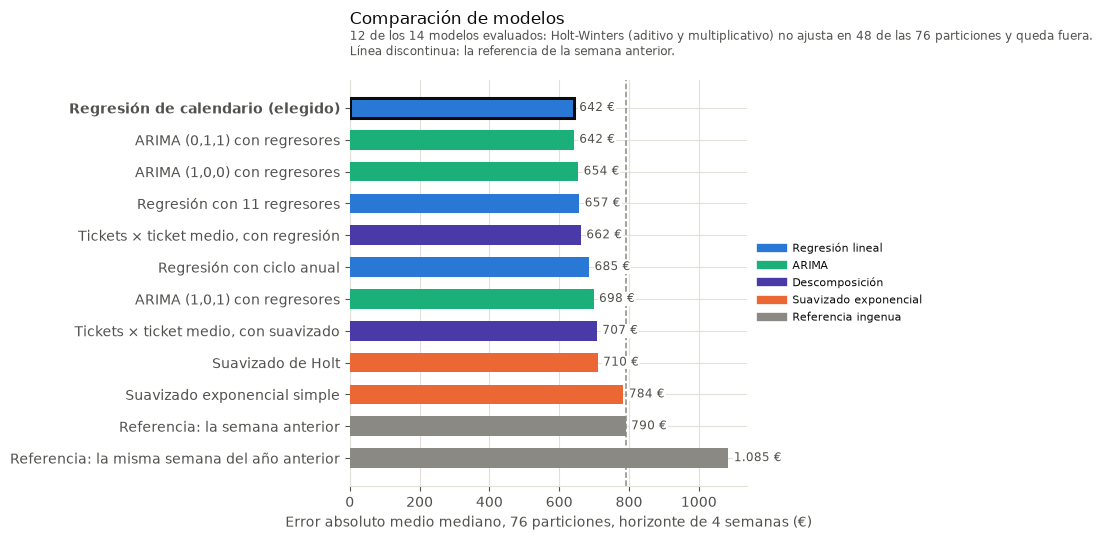

In [25]:
# Figura de la comparacion: todas_mae, las 76 particiones, unica base que
# decide.
comp = tabla.dropna(subset=["todas_mae"]).sort_values("todas_mae")

NOMBRE = {
    "ols_basico": "Regresión de calendario (elegido)",
    "ols_sin_ciclo": "Regresión con 11 regresores",
    "ols_spline": "Regresión con ciclo anual",
    "arima_xreg_011": "ARIMA (0,1,1) con regresores",
    "arima_xreg_100": "ARIMA (1,0,0) con regresores",
    "arima_xreg_101": "ARIMA (1,0,1) con regresores",
    "desc_ols": "Tickets × ticket medio, con regresión",
    "desc_ses": "Tickets × ticket medio, con suavizado",
    "holt": "Suavizado de Holt",
    "ses": "Suavizado exponencial simple",
    "naive_1": "Referencia: la semana anterior",
    "naive_52": "Referencia: la misma semana del año anterior",
}
FAMILIA = {"ols": ("Regresión lineal", AZUL), "arima": ("ARIMA", AQUA),
           "desc": ("Descomposición", VIOLETA), "holt": ("Suavizado exponencial", NARANJA),
           "ses": ("Suavizado exponencial", NARANJA), "naive": ("Referencia ingenua", GRIS)}
assert set(comp.index) <= set(NOMBRE), set(comp.index) - set(NOMBRE)

def familia_de(modelo):
    return FAMILIA[modelo.split("_")[0]]

colores = [familia_de(m)[1] for m in comp.index]
elegido = comp.index == "ols_basico"

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ypos = np.arange(len(comp))
barras = ax.barh(ypos, comp["todas_mae"], color=colores, height=0.62, zorder=3,
                  edgecolor=[TINTA if e else "none" for e in elegido],
                  linewidth=[2.2 if e else 0 for e in elegido])
ax.bar_label(barras, labels=[f"{num(v, 0)} €" for v in comp["todas_mae"]],
             padding=4, fontsize=8.5, color=TINTA2,
             bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
ax.axvline(comp.loc["naive_1", "todas_mae"], color=GRIS, linestyle="--",
           linewidth=1.1, zorder=2)
ax.set_yticks(ypos)
ax.set_yticklabels([NOMBRE[m] for m in comp.index])
for etiqueta, e in zip(ax.get_yticklabels(), elegido):
    if e:
        etiqueta.set_fontweight("bold")
ax.invert_yaxis()
ax.set_xlabel("Error absoluto medio mediano, 76 particiones, horizonte de 4 semanas (€)")
ax.set_title("Comparación de modelos", color=TINTA, loc="left", pad=40)
n_total, n_shown = len(tabla), len(comp)
nota = (f"{n_shown} de los {n_total} modelos evaluados: Holt-Winters (aditivo y "
        "multiplicativo) no ajusta en 48 de las 76 particiones y queda fuera.\n"
        "Línea discontinua: la referencia de la semana anterior.")
ax.text(0, 1.05, nota, transform=ax.transAxes, color=TINTA2, fontsize=8.5, va="bottom")
vistas = []
for m in comp.index:
    if familia_de(m) not in vistas:
        vistas.append(familia_de(m))
leyenda = [plt.Line2D([0], [0], color=c, lw=6, label=l) for l, c in vistas]
ax.legend(handles=leyenda, frameon=False, fontsize=8, loc="center left",
          bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
guardar(fig, "comparacion-modelos")
plt.show()

#### Lo que concluye este notebook

1. El modelo del TFM es `ols_basico`: una regresión lineal sobre el calendario
con las 5 variables significativas al 5 % — constante,
tendencia, horas de cierre en festivo, la semana de Semana Santa y el
acopio de fiesta local.
A cuatro semanas es el que menos se equivoca de los 14 evaluados,
y es el único que se lee en euros.

2. Se equivoca en 642 € sobre una venta típica de 16.022 €:
un 4,0 %. En su peor partición de 76 llega a 1.335 € (8,3 %).
El listón ingenuo se queda en 790 €, así que el modelado vale
149 € de error por semana (18,8 % menos).

3. El horizonte son 4 semanas, y tiene dos motivos.
Es el plazo con el que la tienda prepara el aprovisionamiento de las
fiestas locales —un mes antes—, y a ese horizonte la validación cubre
los doce meses. El pedido ordinario, a 3-4 días, se mide aparte en §9.
A 26 semanas ganaría `ses`. Cambiar el horizonte
cambia qué modelo gana, y por eso la elección hay que justificarla
contra el problema real, no contra el cómodo.

4. Tres cosas se descartaron con medición, y van a la memoria:
- Holt-Winters (§4) no es medible: no ajusta en 48 de 76
particiones, y donde ajusta la estacionalidad empeora el error.
- ARIMA con xreg (§6), con los mismos 5 regresores, empata en la semana
típica pero no mejora, y Box-Jenkins completo (§6) confirma que no hace falta:
641,66 € frente a 641,51 €, y peor partición 1.555 € (vs 1.335 €).
- La descomposición tickets × ticket medio (§7) no aporta: 662 € frente a 642 €.

5. Pero la descomposición sí dio el hallazgo de negocio (§7):
todo el crecimiento es afluencia (tickets 15,9 %) y el gasto
por visita cae un 4,9 % real. Sano en clientela, frágil en cesta.

#### Cómo se lee la tabla, que tiene trampa

- Manda `todas_*` (76 particiones). `comun_*` son solo las 28 en que
ajustaron todos, y no sirve para elegir: al recortar te quedas con las
de entrenamiento más largo, o sea las fáciles.

- Los 2 modelos con NaN no son modelos malos: son no medibles. Es una
afirmación más fuerte que decir que salen peor, y es la que se defiende.

- Dentro de una columna se compara cualquier fila. Entre bloques, nunca.

#### Lo que este notebook todavía no hace

- El §11 ya da el pronóstico de septiembre; el resto es backtesting.
- El modelo explica el 68 % de la variación (R² 0,678).

---

## 9 · El horizonte que necesita la tienda

Las secciones anteriores miden a **cuatro semanas**: es el plazo con el que la
tienda prepara el **aprovisionamiento de las fiestas locales**, y el horizonte
que deja 76 particiones cubriendo los doce meses del año.

**El pedido ordinario mira mucho menos lejos.** La tienda hace **dos pedidos a
la semana** a su central de compras:

| Pedido | Entrega | Cubre |
|---|---|---:|
| **martes** | jueves | jueves, viernes, sábado → **3 días** |
| **jueves** | lunes | lunes, martes, miércoles → **4 días** |

Para ese pedido no hace falta saber qué pasará dentro de cuatro semanas; para
el de las fiestas, sí.

Así que la pregunta es: **¿cuánto mejora la predicción cuando solo se le pide
la semana siguiente?** Se mide en **las mismas particiones**, para no mezclar el
efecto del horizonte con el del tramo de serie. **Se añade h=10**, porque es el
horizonte que usa de verdad la predicción de septiembre de la sección 11.

In [26]:
elegido = "ols_basico"
mejor_tipico = tabla["todas_mae"].idxmin()
liston = tabla.loc["naive_1", "todas_mae"]
venta_tipica = y.median()
mae_el = tabla.loc[elegido, "todas_mae"]
peor_el = tabla.loc[elegido, "todas_peor"]
n_part = detalle_todo["origen"].nunique()

# Los cortes del horizonte más largo, que es el restrictivo: así los cuatro
# horizontes se miden exactamente sobre las mismas particiones.
cortes = baselines.origenes_particiones(len(serie), horizonte=10,
                                        n_particiones=len(serie))

por_horizonte = []
for h in (1, 2, 4, 10):
    d = modelos.evaluar(serie, ["baselines", "ols_basico", "ses"],
                        horizonte=h, origenes=cortes)
    por_horizonte.append(d.groupby("modelo")["mae"].median().rename(f"h={h}"))

horizontes = pd.concat(por_horizonte, axis=1).round(0)
horizontes = horizontes.loc[["ols_basico", "ses", "naive_1", "naive_52"]]
display(horizontes)

meses_cubiertos = pd.to_datetime(serie["periodo_inicio"]).iloc[[c - 1 for c in cortes]].dt.month.nunique()
print(f"{len(cortes)} particiones, las mismas en las cuatro columnas "
      f"({meses_cubiertos} meses distintos representados).")

# El h=4 de referencia (642 €) se mide con h=4 como restrictivo, 76
# particiones.
cortes_oficial = baselines.origenes_particiones(len(serie), horizonte=4,
                                                n_particiones=len(serie))
oficial_h4 = modelos.evaluar(serie, ["ols_basico"], horizonte=4,
                             origenes=cortes_oficial)["mae"].median()


,h=1,h=2,h=4,h=10
modelo,,,,
ols_basico,"514,00","565,00","659,00","656,00"
ses,"735,00","782,00","755,00","824,00"
naive_1,"791,00","874,00","790,00","854,00"
naive_52,"1.001,00","1.118,00","1.104,00","1.227,00"


64 particiones, las mismas en las cuatro columnas (12 meses distintos representados).


#### El horizonte corto es más fácil, y es el que pide el negocio

A una semana el modelo se equivoca en 514 € sobre una venta
típica de 16.022 €: un 3,2 %.
A cuatro semanas son 659 € (4,1 %).
A diez semanas son 656 € (4,1 %).
Acortar el horizonte de 4 a 1 mejora el error un 22,0 %.

Y el orden no cambia en ninguno de los cuatro horizontes: el modelo de
calendario gana siempre, así que la elección del modelo no depende de
este número.

1. Este h=4 (659 €) no es el h=4 «oficial» de la memoria
(642 €): aquí se mide sobre las 64 particiones que dejan
sitio para diez semanas, no las 76 de siempre. Es un efecto de
ventana: cambiar el
horizonte cambia qué tramo de la serie se examina.

2. El peor caso entre columnas no es comparable. A h=10 el MAE de cada
partición promedia diez semanas y a h=1 una sola, así que una mala
semana se diluye mucho más en un caso que en otro. La mediana sí lo es.

3. Y el más importante para el §11: esta tabla prueba h=1, h=2, h=4 y
h=10 — no h=5 a h=9, que es justo donde caen las semanas de fiesta de
septiembre. Que el error no se dispare entre la semana 4 y la 10 da
confianza, pero no es lo mismo que haber medido la semana 7 en concreto.

---

## 10 · El calendario de folletos: el regresor que no entra, y por qué

Era el único regresor determinista que le faltaba al modelo. La tienda dio la
regla y la confirmó dos veces:

> *«Todas las ofertas se activan en martes y duran 12 días. Y son
> consecutivas, es decir, cada 2 semanas se activa 1 folleto nuevo.»*

Ciclo de **14 días**: 12 de campaña, de martes al sábado de la semana
siguiente, y **2 de hueco, domingo y lunes**.

**La regla se cumple, pero con un salto.** Los folletos publicados por la
cadena (`datos_externos/folletos_coviran.csv`, zona de Almería) muestran que
**la Navidad de 2024 corrió el ciclo una semana**. Por eso el calendario de
`features.dias_de_campana` tiene tres tramos. Primero se comprueba que cada
folleto conocido cae en el calendario:

In [27]:
h10 = horizontes.loc["ols_basico", "h=10"]
h4 = horizontes.loc["ols_basico", "h=4"]
h1 = horizontes.loc["ols_basico", "h=1"]
mejora = 100 * (h4 - h1) / h4
venta = serie["venta_neta"].median()

folletos = features.verificar_folletos()
print(f"Folletos con fecha conocida: {len(folletos)} "
      f"({(folletos['tipo_fuente'] == 'oficial').sum()} oficiales de la zona de Almería, "
      f"{(folletos['tipo_fuente'] == 'tienda').sum()} del correo de la tienda, "
      f"{(folletos['tipo_fuente'] == 'secundaria').sum()} de fuentes secundarias).")
print(f"Coinciden día a día con el calendario: {folletos['coincide'].sum()} de {len(folletos)}.")

campana_7 = features.campana_por_semana(serie["periodo_inicio"], solo_abiertos=False)
campana_6 = features.campana_por_semana(serie["periodo_inicio"], solo_abiertos=True)
placebo_6 = features.campana_por_semana(serie["periodo_inicio"], desfase=7)

print("\nDías de campaña por semana, contando los 7 días:")
print(campana_7.value_counts().to_string())
print("\nContando solo los días de apertura (el domingo cierra):")
print(campana_6.value_counts().to_string())
espejo = int(((campana_6 + placebo_6) == 11).sum())

Folletos con fecha conocida: 22 (3 oficiales de la zona de Almería, 2 del correo de la tienda, 17 de fuentes secundarias).
Coinciden día a día con el calendario: 22 de 22.



Días de campaña por semana, contando los 7 días:
dias_campana
6    132
7      3

Contando solo los días de apertura (el domingo cierra):
dias_campana
6    68
5    67


Contando los 7 días, 132 de las 135 semanas tienen 6 de campaña: el regresor es casi constante.
Contando los de apertura alterna 5 y 6, y el calendario corrido una semana es '11 - el real' en 134 de las 135 semanas.

**Contando los siete días, el regresor es casi constante**, y una variable así
no tiene variación que explicar. Solo las semanas de la Navidad de 2024 se
salen del patrón.

Contando solo los días de apertura sí varía, porque el domingo de hueco cae en
día cerrado y el lunes no: **alterna 5 y 6**.

Pero una alternancia de periodo 2 hay que **falsarla antes de creérsela**: si
lo que recoge es cualquier oscilación quincenal y no el folleto, la versión con
el calendario corrido una semana ajustará igual de bien. Esa es
`ols_promo_desfase`, que no es un modelo sino **la prueba de control**.

In [28]:
promo = modelos.evaluar(serie, ["ols_basico", "ols_promo_basico", "ols_promo_desfase_basico"])
display(tabla_de(promo)[["mae_mediano", "mae_medio", "peor_particion", "particiones"]])

# Y el coeficiente, ajustado sobre las 135 semanas: cuánto vale un día de folleto,
# sobre el modelo elegido.
X_promo = modelos.matrices(serie)["campana_basico"]
ajuste_promo = sm.OLS(serie["venta_neta"].to_numpy(float),
                      sm.add_constant(X_promo)).fit()
ic = ajuste_promo.conf_int().loc["dias_campana"]
print(f"\ndias_campana: {num(ajuste_promo.params['dias_campana'], 1)} €/día  ·  "
      f"p = {num(ajuste_promo.pvalues['dias_campana'], 3)}  ·  "
      f"IC95% [{num(ic[0], 0)}, {num(ic[1], 0)}]")

,mae_mediano,mae_medio,peor_particion,particiones
modelo,,,,
ols_basico,"642,00","644,00","1.335,00",76
ols_promo_desfase_basico,"652,00","651,00","1.324,00",76
ols_promo_basico,"654,00","653,00","1.337,00",76



dias_campana: 128,9 €/día  ·  p = 0,366  ·  IC95% [-152, 410]


In [29]:
t = tabla_de(promo)["mae_mediano"]
p_promo = ajuste_promo.pvalues["dias_campana"]
X_placebo = modelos.matrices(serie)["campana_desfase_basico"]
ajuste_placebo = sm.OLS(serie["venta_neta"].to_numpy(float), sm.add_constant(X_placebo)).fit()

print()
dif_promo = t["ols_promo_basico"] - t["ols_basico"]

#### El calendario de folleto no entra en el modelo
1. Empeora la predicción: 654,00 € con él, 642,00 € sin él
(12,00 € más de error mediano en las 76 particiones).

2. El coeficiente no se distingue de cero: 128,91 €/día,
p = 0,366, IC95% [-152, 410] €.

3. Y no se distingue de su placebo: con el calendario corrido una semana el
error es 652,00 € y el coeficiente -128,11 €/día (p = 0,368):
casi el mismo efecto con el signo cambiado. Lo que recoge el regresor es una
alternancia de dos semanas, no el folleto.

Lo que esto no dice: que las promociones no vendan. Dice que su calendario
no tiene variación semanal que explotar. Lo que cambia entre campañas es la
intensidad —qué artículos, qué descuento— y eso no está en ninguna fuente del TFM.

---

## 11 · Predicción futura

Todo lo anterior es *backtesting*: las 76 particiones caen **dentro** de la
ventana observada. Aquí se produce lo que la tienda puede usar: cifras para
semanas que **todavía no han ocurrido**.

**El objetivo: dimensionar el aprovisionamiento de las fiestas locales de
septiembre de 2026.** Los lunes 21 y 28 son fiesta local y la tienda **cierra
entera**; la semana o las dos previas hay **aprovisionamiento**: la gente
compra antes.

**Salvedad, marcada en la tabla.** El modelo está validado a **1, 2, 4 y 10
semanas** (sección 9). Septiembre cae entre **6 y 9 semanas** después del
último dato: dentro del rango que acotan las medidas de 4 y 10, pero sin un
punto medido exactamente ahí. La columna `validado` lo distingue. La serie
termina el 2026-08-02.

**El intervalo es de predicción, no de confianza**: acota dónde estará *esa
semana concreta*, no su media.

In [30]:
# Pronóstico hasta pasadas las fiestas de septiembre. h=10 llega al 11 de
# octubre.
H = 10
fut = modelos.predecir_futuro(serie, h=H, escenario="cierre")
HORIZONTES_MEDIDOS = {1, 2, 4, 10}
h_fut = np.arange(1, H + 1)
fut["validado"] = np.where(np.isin(h_fut, list(HORIZONTES_MEDIDOS)), "sí",
                           np.where(h_fut < 4, "entre 2 y 4", "entre 4 y 10"))

# Efecto del calendario en euros = predicción − lo que se vendería esa semana
# sin ningún festivo (solo nivel + tendencia).
_origen = pd.to_datetime(serie["periodo_inicio"]).min()
_Xo = features.construir(serie["periodo_inicio"], features.cargar_festivos(),
                         origen=_origen, leads=(), ventana_pascua=0)
_aj = sm.OLS(serie["venta_neta"].to_numpy(float),
             sm.add_constant(_Xo, has_constant="add")).fit()
_Xf = features.construir(fut["periodo_inicio"],
                         features.cargar_festivos_escenario("cierre"),
                         origen=_origen, leads=(), ventana_pascua=0)[_Xo.columns]
_Xb = _Xf.copy()
_Xb[[c for c in _Xb.columns if c != "tendencia"]] = 0.0
fut["efecto_calendario"] = (
    _aj.predict(sm.add_constant(_Xf, has_constant="add"))
    - _aj.predict(sm.add_constant(_Xb, has_constant="add"))).to_numpy()

display(fut.set_index("periodo_inicio")[
    ["periodo_fin", "prediccion", "lo", "hi", "horas_cierre_festivo",
     "efecto_calendario", "validado"]].round(
    {"prediccion": 0, "lo": 0, "hi": 0, "horas_cierre_festivo": 0, "efecto_calendario": 0}))

,periodo_fin,prediccion,lo,hi,horas_cierre_festivo,efecto_calendario,validado
periodo_inicio,,,,,,,
2026-08-03,2026-08-09,"17.387,00","15.755,00","19.020,00","0,00","0,00",sí
2026-08-10,2026-08-16,"16.389,00","14.748,00","18.031,00","5,00","-1.015,00",sí
2026-08-17,2026-08-23,"17.422,00","15.788,00","19.055,00","0,00","0,00",entre 2 y 4
2026-08-24,2026-08-30,"17.439,00","15.805,00","19.073,00","0,00","0,00",sí
2026-08-31,2026-09-06,"17.456,00","15.821,00","19.090,00","0,00","0,00",entre 4 y 10
2026-09-07,2026-09-13,"21.319,00","19.501,00","23.138,00","0,00","3.846,00",entre 4 y 10
2026-09-14,2026-09-20,"21.336,00","19.518,00","23.155,00","0,00","3.846,00",entre 4 y 10
2026-09-21,2026-09-27,"15.884,00","14.218,00","17.549,00","8,00","-1.624,00",entre 4 y 10
2026-09-28,2026-10-04,"15.901,00","14.235,00","17.567,00","8,00","-1.624,00",entre 4 y 10


  guardada 03-prediccion-futura.png / .svg


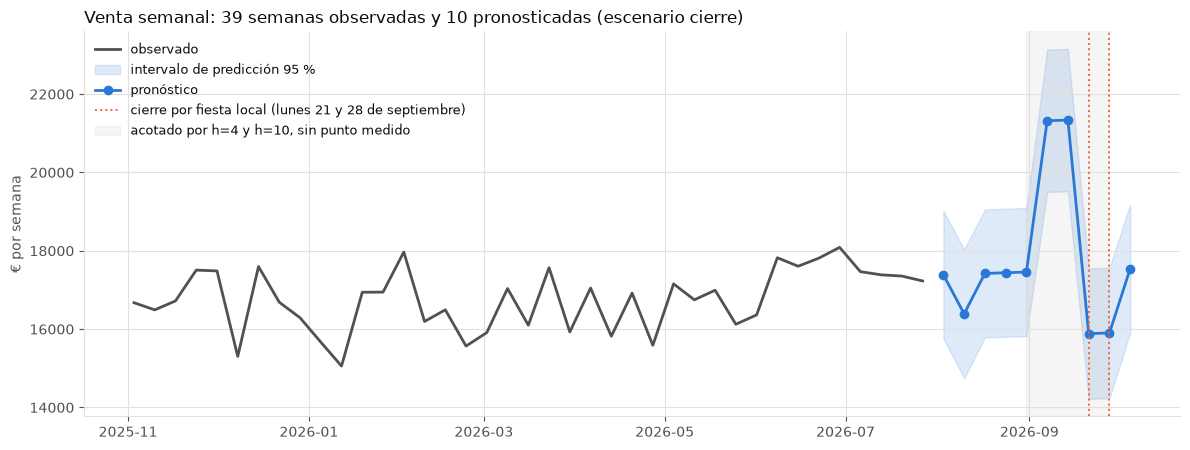

In [31]:
fig, ax = plt.subplots(figsize=(12, 4.6))
hist = serie.tail(39)
ax.plot(hist["periodo_inicio"], hist["venta_neta"], color=TINTA2, label="observado")
ax.fill_between(fut["periodo_inicio"], fut["lo"], fut["hi"],
                color=AZUL, alpha=0.15, label="intervalo de predicción 95 %")
ax.plot(fut["periodo_inicio"], fut["prediccion"], color=AZUL, marker="o", label="pronóstico")

# Las dos semanas de fiesta local y el tramo acotado por h=4 y h=10 pero sin
# punto medido exactamente ahí (§9).
for i, f in enumerate(("2026-09-21", "2026-09-28")):
    ax.axvline(pd.Timestamp(f), color=NARANJA, linestyle=":", linewidth=1.4,
               label="cierre por fiesta local (lunes 21 y 28 de septiembre)" if i == 0 else None)
lim = fut.loc[fut["validado"] == "entre 4 y 10", "periodo_inicio"].min()
ax.axvspan(lim, fut.loc[fut["validado"] == "entre 4 y 10", "periodo_inicio"].max(),
           color=GRIS, alpha=0.08, label="acotado por h=4 y h=10, sin punto medido")

ax.set_title("Venta semanal: 39 semanas observadas y 10 pronosticadas (escenario cierre)",
             loc="left", fontsize=12, color=TINTA)
ax.set_ylabel("€ por semana")
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.tight_layout()
guardar(fig, "prediccion-futura")
plt.show()

In [32]:
# Backtest: ¿qué habría dicho el modelo para septiembre de 2024 y 2025,
# ajustado solo con los datos hasta finales de agosto de cada año?
_d = pd.to_datetime(serie["periodo_inicio"])
_y = serie["venta_neta"].to_numpy(float)
_fest = features.cargar_festivos()
_o0 = _d.min()

def backtest_sept(anio, n=7, fl=True):
    corte = int((_d < f"{anio}-08-24").sum())
    itr = serie["periodo_inicio"].iloc[:corte]
    ite = serie["periodo_inicio"].iloc[corte:corte + n]
    Xtr = features.construir(itr, _fest, origen=_o0, fiesta_local=fl,
                             leads=(), ventana_pascua=0)
    Xte = features.construir(ite, _fest, origen=_o0, fiesta_local=fl,
                             leads=(), ventana_pascua=0)[Xtr.columns]
    aj = sm.OLS(_y[:corte], sm.add_constant(Xtr, has_constant="add")).fit()
    pr = np.asarray(aj.predict(sm.add_constant(Xte, has_constant="add")))
    re = _y[corte:corte + n]
    return pd.DataFrame({"semana": ite.dt.strftime("%d-%m").to_numpy(),
                         "predicho": pr.round(0), "real": re.round(0),
                         "error": (re - pr).round(0)})

res = {}
for anio in (2024, 2025):
    res[anio] = {"con": backtest_sept(anio, fl=True), "sin": backtest_sept(anio, fl=False)}
    print(f"Septiembre {anio}: error en la semana de acopio  "
          f"sin término +{num(res[anio]['sin']['error'].max(), 0)} €  →  "
          f"con término {num(res[anio]['con']['error'].max(), 0, signo=True)} €")
    display(res[anio]["con"])

infra24 = res[2024]["sin"]["error"].max()
infra25 = res[2025]["sin"]["error"].max()
print(f"En 2024 el término no tenía datos previos (no ayuda). En 2025, estimado")
print(f"solo con 2024, recorta el error de la semana de acopio de +{num(infra25, 0)} € a "
      f"+{num(res[2025]['con']['error'].max(), 0)} €.")

Septiembre 2024: error en la semana de acopio  sin término +5.595 €  →  con término +5.595 €


,semana,predicho,real,error
0,26-08,"15.838,00","14.635,00","-1.203,00"
1,02-09,"15.859,00","16.907,00","1.049,00"
2,09-09,"15.880,00","21.475,00","5.595,00"
3,16-09,"15.067,00","13.358,00","-1.709,00"
4,23-09,"15.921,00","16.159,00","237,00"
5,30-09,"14.275,00","13.974,00","-301,00"
6,07-10,"15.755,00","15.172,00","-582,00"


Septiembre 2025: error en la semana de acopio  sin término +5.615 €  →  con término +2.192 €


,semana,predicho,real,error
0,25-08,"16.736,00","17.467,00","731,00"
1,01-09,"16.756,00","16.643,00","-113,00"
2,08-09,"20.255,00","19.072,00","-1.183,00"
3,15-09,"20.275,00","22.467,00","2.192,00"
4,22-09,"15.009,00","14.560,00","-449,00"
5,29-09,"15.029,00","14.998,00","-31,00"
6,06-10,"16.857,00","16.503,00","-354,00"


En 2024 el término no tenía datos previos (no ayuda). En 2025, estimado
solo con 2024, recorta el error de la semana de acopio de +5.615 € a +2.192 €.


In [33]:
acopio = fut[(fut["efecto_calendario"] > 500) & (fut["periodo_inicio"] >= "2026-09-01")]
cierres = fut[(fut["horas_cierre_festivo"] > 0) & (fut["periodo_inicio"] >= "2026-09-01")]

print("=" * 70)
print("Pronóstico para el aprovisionamiento de septiembre")
print("=" * 70)
print()
print("El pronóstico arranca al final de la serie (2026-08-02). Las semanas que")
print("importan son las de septiembre: cae entre las semanas 6 y 9, dentro del")
print("rango que acotan h=4 y h=10 (§9), sin un punto medido justo ahí.")
print(f"Predicción entre {num(fut['prediccion'].min(), 0)} y {num(fut['prediccion'].max(), 0)} € "
      f"por semana. Intervalo de predicción: ±{num((fut['hi'] - fut['lo']).median() / 2, 0)} € de mediana,")
semi = (fut['hi'] - fut['lo']) / 2
print(f"más ancho en las semanas de acopio (±{num(semi[acopio.index].max(), 0)} €) "
      f"y de cierre (±{num(semi[cierres.index].max(), 0)} €).")
print()
print("Semanas de acopio — reforzar stock. El modelo dice:")
for _, r in acopio.iterrows():
    print(f"  semana del {r['periodo_inicio']:%d-%m}: {num(r['prediccion'], 0)} € "
          f"({num(r['efecto_calendario'], 0, signo=True)} € sobre una semana normal)")
print()
print("Semanas de lunes cerrado (21 y 28):")
for _, r in cierres.iterrows():
    print(f"  semana del {r['periodo_inicio']:%d-%m}: {num(r['prediccion'], 0)} € "
          f"({num(r['efecto_calendario'], 0, signo=True)} €)")
print()
# Las dos semanas de acopio de 2025 en el backtest con el término (celda 64).
_ite25 = serie["periodo_inicio"].iloc[int((_d < "2025-08-24").sum()):][:7]
_marca25 = features.construir(_ite25, _fest, origen=_o0, fiesta_local=True, leads=(),
                              ventana_pascua=0)["fiesta_local_acopio"].to_numpy() == 1
_ac25 = res[2025]["con"][_marca25]

Pronóstico para el aprovisionamiento de septiembre

El pronóstico arranca al final de la serie (2026-08-02). Las semanas que
importan son las de septiembre: cae entre las semanas 6 y 9, dentro del
rango que acotan h=4 y h=10 (§9), sin un punto medido justo ahí.
Predicción entre 15.884 y 21.336 € por semana. Intervalo de predicción: ±1.639 € de mediana,
más ancho en las semanas de acopio (±1.819 €) y de cierre (±1.666 €).

Semanas de acopio — reforzar stock. El modelo dice:
  semana del 07-09: 21.319 € (+3.846 € sobre una semana normal)
  semana del 14-09: 21.336 € (+3.846 € sobre una semana normal)

Semanas de lunes cerrado (21 y 28):
  semana del 21-09: 15.884 € (-1.624 €)
  semana del 28-09: 15.901 € (-1.624 €)



El término de acopio acierta el total de las dos semanas, no el reparto.
Estima +3.846 € en cada una de las dos semanas: es un solo
indicador, así que les da el mismo efecto. En el backtest de 2025, las dos
juntas: 40.530 € previstos frente a 41.539 € reales; pero la
1.ª semana -1.183 € y la 2.ª +2.192 €. La semana justo
antes de la fiesta es la fuerte. Separar el indicador exigiría estimar
cada semana con dos septiembres: no se hace. Para el pedido, repartir el
total previsto cargando la segunda semana.

Las semanas de lunes cerrado se predicen bien: esperar unos 1.624 € menos
que una semana normal, y no reponer de más el martes.

### Reparto por departamento

**No se modela cada departamento por separado.** En 2,6 años las cuotas de los
departamentos grandes se mueven alrededor de un punto, así que **repartir la
predicción del total según la cuota reciente de cada departamento da el
detalle sin un modelo más**. Cada serie de departamento es además más ruidosa
que el total (coeficiente de variación del 10-20 % frente al 9 % del agregado), y
su importe va con IVA.

La cuota se calcula sobre las **últimas 26 semanas**.

> **Salvedad:** el reparto supone que el aprovisionamiento de las fiestas se
> distribuye como una semana normal. Probablemente charcutería, bebidas y
> panadería suben algo más; como primera aproximación para el pedido es
> razonable.

In [34]:
dep = pd.read_parquet("../datos_limpio/serie_semanal_departamentos.parquet")
dep["periodo_inicio"] = pd.to_datetime(dep["periodo_inicio"])

# Cuota de cada departamento sobre las últimas 26 semanas; los residuales (<1 %)
# se agrupan en "otros".
reciente = dep[dep["periodo_inicio"] >= dep["periodo_inicio"].max() - pd.Timedelta(weeks=26)]
por_dep = reciente.groupby("departamento")["importe"].sum()
cuota = (por_dep / por_dep.sum()).sort_values(ascending=False)
cuota = pd.concat([cuota[cuota >= 0.01], pd.Series({"OTROS": cuota[cuota < 0.01].sum()})])

# Reparto del pronóstico de septiembre: una fila por semana, columnas por departamento.
sep = fut[fut["periodo_inicio"] >= "2026-09-01"].set_index("periodo_inicio")
pred = sep["prediccion"].to_numpy()
reparto = pd.DataFrame({d: (pred * q).round(0) for d, q in cuota.items()},
                       index=sep.index.strftime("%d-%m"))
reparto.insert(0, "TOTAL", sep["prediccion"].round(0).to_numpy())
display(reparto)

print("Cuota reciente (últimas 26 semanas):")
for d, q in cuota.items():
    print(f"  {d:22s} {num(100 * q, 1)} %")

,TOTAL,ULTRAMARINOS,CARNICERIA,BEBIDAS,FRUTAS Y VERDURA,DROGUERIA Y PERF,PANADERIA PASTEL,CONGELADOS,CHARCUTERIA CORT,LACTEOS,OTROS
periodo_inicio,,,,,,,,,,,
07-09,"21.319,00","6.547,00","3.430,00","2.877,00","1.985,00","1.713,00","1.492,00","1.025,00","895,00","880,00","475,00"
14-09,"21.336,00","6.553,00","3.433,00","2.879,00","1.987,00","1.714,00","1.493,00","1.026,00","895,00","880,00","475,00"
21-09,"15.884,00","4.878,00","2.556,00","2.143,00","1.479,00","1.276,00","1.111,00","764,00","666,00","655,00","354,00"
28-09,"15.901,00","4.883,00","2.558,00","2.146,00","1.481,00","1.278,00","1.113,00","765,00","667,00","656,00","354,00"
05-10,"17.542,00","5.387,00","2.822,00","2.367,00","1.634,00","1.410,00","1.228,00","844,00","736,00","724,00","391,00"


Cuota reciente (últimas 26 semanas):
  ULTRAMARINOS           30,7 %
  CARNICERIA             16,1 %
  BEBIDAS                13,5 %
  FRUTAS Y VERDURA       9,3 %
  DROGUERIA Y PERF       8,0 %
  PANADERIA PASTEL       7,0 %
  CONGELADOS             4,8 %
  CHARCUTERIA CORT       4,2 %
  LACTEOS                4,1 %
  OTROS                  2,2 %


Para el pedido de las semanas de acopio (7-13 y 14-20 de septiembre),
los tres departamentos que más suben en euros son ultramarinos,
carnicería y bebidas. La salvedad de arriba: charcutería, bebidas y
panadería probablemente pesan algo más de lo que dice su cuota media.

---

## Conclusiones

- **Un modelo sencillo basta.** La regresión de calendario con cinco términos
  gana a los suavizados, a los ARIMA y a la descomposición tickets × ticket
  medio, y además se puede explicar en euros.
- **El residuo es ruido**: no queda estructura temporal que un ARIMA pueda
  aprovechar.
- **El calendario de folletos no aporta**: la prueba de falsación lo descarta.
- **La predicción se mantiene a 1, 2, 4 y 10 semanas**, así que sirve tanto
  para el pedido ordinario como para el de las fiestas.

**Ampliación posible:** probar Prophet, que no se llegó a evaluar.

---

## 12 · Ficha resumen del modelo

Una figura que resume en una sola imagen la metodología, el modelo, la
variable objetivo, el alcance de los datos, la validación y el resultado. No
calcula nada nuevo: reutiliza las variables de la sección 8 (`elegido`,
`mae_el`, `peor_el`, `liston`, `venta_tipica`, `n_part`, `ajuste`) en vez de
repetir las cifras a mano.

  guardada 03-esquema-modelo.png / .svg


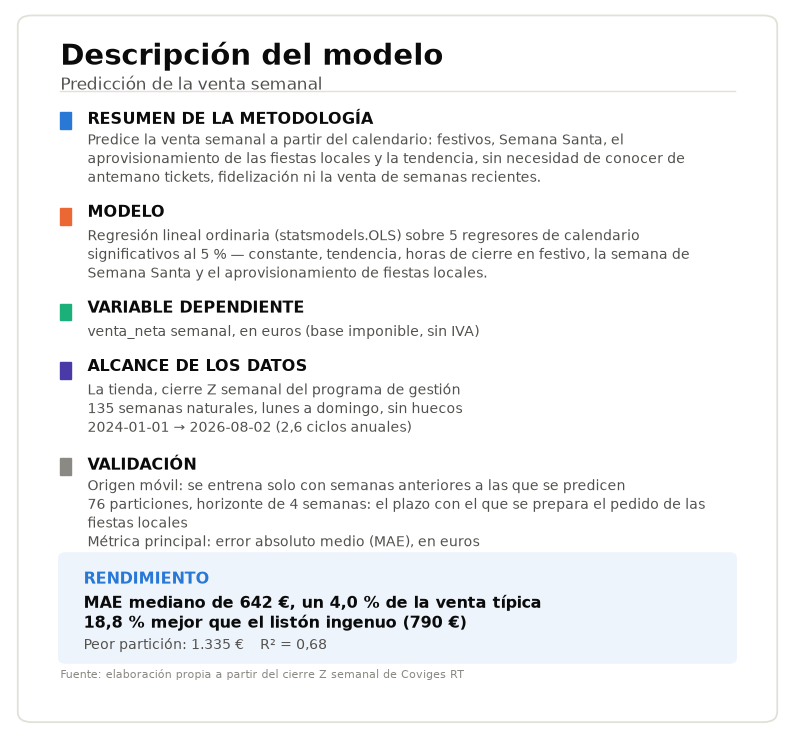

In [35]:
from matplotlib.patches import FancyBboxPatch, Rectangle
import textwrap

ALTO = 12.3
fig, ax = plt.subplots(figsize=(10, 9.33))
ax.set_xlim(0, 10)
ax.set_ylim(0, ALTO)
ax.axis("off")

marco = FancyBboxPatch((0.12, 0.12), 9.76, ALTO - 0.24, boxstyle="round,pad=0.02,rounding_size=0.18",
                       linewidth=1.3, edgecolor=REJILLA, facecolor="white", zorder=0)
ax.add_patch(marco)

TOP = ALTO - 0.55
ax.text(0.65, TOP, "Descripción del modelo", fontsize=21, fontweight="bold",
        color=TINTA, va="top", ha="left")
ax.text(0.65, TOP - 0.58, "Predicción de la venta semanal",
        fontsize=12.5, color=TINTA2, va="top", ha="left")
ax.plot([0.65, 9.35], [TOP - 0.85, TOP - 0.85], color=REJILLA, linewidth=1)

LABEL_H, LINE_H, GAP, ANCHO_TEXTO = 0.42, 0.32, 0.26, 88

def bloque(y_top, etiqueta, color, lineas):
    ax.add_patch(Rectangle((0.65, y_top - LABEL_H + 0.08), 0.14, 0.28, color=color, zorder=2))
    ax.text(1.00, y_top, etiqueta, fontsize=11.5, fontweight="bold", color=TINTA, va="top", ha="left")
    yy = y_top - LABEL_H
    for linea in lineas:
        for sub in textwrap.wrap(linea, ANCHO_TEXTO):
            ax.text(1.00, yy, sub, fontsize=10.3, color=TINTA2, va="top", ha="left")
            yy -= LINE_H
    return yy - GAP

y_cur = TOP - 1.15
y_cur = bloque(y_cur, "RESUMEN DE LA METODOLOGÍA", AZUL,
    ["Predice la venta semanal a partir del calendario: festivos, Semana Santa, "
     "el aprovisionamiento de las fiestas locales y la tendencia, sin necesidad de conocer de "
     "antemano tickets, fidelización ni la venta de semanas recientes."])
y_cur = bloque(y_cur, "MODELO", NARANJA,
    ["Regresión lineal ordinaria (statsmodels.OLS) sobre 5 regresores de calendario "
     "significativos al 5 % — constante, tendencia, horas de cierre en festivo, la "
     "semana de Semana Santa y el aprovisionamiento de fiestas locales."])
y_cur = bloque(y_cur, "VARIABLE DEPENDIENTE", AQUA,
    ["venta_neta semanal, en euros (base imponible, sin IVA)"])

fin_semana = serie["periodo_inicio"].max() + pd.Timedelta(days=6)
y_cur = bloque(y_cur, "ALCANCE DE LOS DATOS", VIOLETA,
    [f"La tienda, cierre Z semanal del programa de gestión",
     f"{len(serie)} semanas naturales, lunes a domingo, sin huecos",
     f"{serie['periodo_inicio'].min():%Y-%m-%d} → {fin_semana:%Y-%m-%d} (2,6 ciclos anuales)"])

y_cur = bloque(y_cur, "VALIDACIÓN", GRIS,
    ["Origen móvil: se entrena solo con semanas anteriores a las que se predicen",
     f"{n_part} particiones, horizonte de {baselines.HORIZONTE} semanas: el plazo con "
     "el que se prepara el pedido de las fiestas locales",
     "Métrica principal: error absoluto medio (MAE), en euros"])

alto_caja = 1.85
caja_top = y_cur + GAP
caja = FancyBboxPatch((0.65, caja_top - alto_caja), 8.7, alto_caja,
                      boxstyle="round,pad=0.03,rounding_size=0.1", linewidth=0,
                      facecolor="#eef4fc", zorder=1)
ax.add_patch(caja)
yy = caja_top - 0.30
ax.text(0.95, yy, "RENDIMIENTO", fontsize=11.5, fontweight="bold", color=AZUL, va="top")
yy -= 0.40
ax.text(0.95, yy, f"MAE mediano de {num(mae_el,0)} €, un {num(100*mae_el/venta_tipica,1)} % "
        "de la venta típica", fontsize=11.5, fontweight="bold", color=TINTA, va="top")
yy -= 0.34
ax.text(0.95, yy, f"{num(100*(liston-mae_el)/liston,1)} % mejor que el listón ingenuo "
        f"({num(liston,0)} €)", fontsize=11.5, fontweight="bold", color=TINTA, va="top")
yy -= 0.40
ax.text(0.95, yy, f"Peor partición: {num(peor_el,0)} €    R² = {num(ajuste.rsquared,2)}",
        fontsize=10.3, color=TINTA2, va="top")

pie_y = caja_top - alto_caja - 0.12
ax.text(0.65, pie_y, "Fuente: elaboración propia a partir del cierre Z semanal de Coviges RT",
        fontsize=8, color=GRIS, va="top", ha="left")

guardar(fig, "esquema-modelo")
plt.show()
